# 04 — Evaluation, Visualization and Project Integration

**Project:** Indoor Positioning via Signal Strength Features and Deep Multitask Learning  
**Member 5** — Evaluation, visualizations and project integration

---

## Notebook Objectives

This notebook implements the comprehensive evaluation pipeline for the indoor positioning system.
All models were trained in **Notebook 03** and their per-sample validation predictions were
persisted to `results/metrics/validation_predictions.csv`. We load those predictions here and:

1. **Define evaluation metrics** (Task 1) — accuracy, precision, recall, F1, MAE, RMSE, R²,
   mean / median / P90 Euclidean position error.
2. **Evaluate building classification** (Task 2) — accuracy, precision, recall, macro-F1, confusion matrix.
3. **Evaluate floor classification** (Task 3) — accuracy, macro-F1, confusion matrix.
4. **Evaluate coordinate prediction** (Task 4) — per-coordinate MAE, Euclidean distance error,
   median and P90 positioning error.
5. **Building-wise and floor-wise error breakdowns** (Task 5).
6. **Generate visualizations** (Task 6) — confusion matrices, actual vs predicted coordinates,
   spatial error plots, error distributions, CDF curves, model comparison charts, floor-error heatmaps.
7. **Failure case analysis** (Task 7) — worst predictions, floor confusion patterns, sparse-coverage areas.
8. **Project integration** (Tasks 8–9) — verify notebook order, reproducibility, and export final results.

All reusable evaluation functions live in `src/evaluate.py`.

## 1. Setup, Imports, and Configuration

In [1]:
from pathlib import Path
import sys
import json
import warnings
import os

os.environ["MPLCONFIGDIR"] = "/tmp/matplotlib"
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Resolve project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluate import (
    position_errors,
    evaluate_classifier,
    evaluate_regressor,
    evaluate_building_floor,
    building_wise_breakdown,
    floor_wise_breakdown,
    failure_case_analysis,
    plot_confusion_matrix,
    plot_actual_vs_predicted,
    plot_spatial_errors,
    plot_error_distribution,
    plot_model_comparison,
    plot_error_cdf,
    plot_floor_error_heatmap,
    get_classification_report_df,
)

# Matplotlib style
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.facecolor": "white",
})
sns.set_style("whitegrid")

# Output directories
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
REPORTS_DIR = PROJECT_ROOT / "report" / "model_evaluation"

for d in [METRICS_DIR, FIGURES_DIR, REPORTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT.resolve()}")
print(f"Figures dir:  {FIGURES_DIR.resolve()}")
print("Setup complete.")

Matplotlib is building the font cache; this may take a moment.


Project root: /Users/soumyatiwari/Desktop/indoor-wifi-positioning
Figures dir:  /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/figures
Setup complete.


## 2. Load Validation Predictions and Reconstruct Model Outputs

Notebook 03 exported per-sample predictions for every model to
`validation_predictions.csv`.  We reconstruct the `predictions` dict
so that `src/evaluate.py` functions can consume them identically to
how Notebook 03 produced them.

In [2]:
# Load predictions exported by Notebook 03
pred_df = pd.read_csv(METRICS_DIR / "validation_predictions.csv")
print(f"Loaded validation predictions: {pred_df.shape[0]} samples, {pred_df.shape[1]} columns")

# True labels
REGRESSION_TARGETS = ["LONGITUDE", "LATITUDE"]
y_val = pred_df[["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE"]].copy()

# Model name to column prefix mapping (derived from NB03 safe-name convention)
MODEL_MAP = {
    "Dummy Baseline (Mode/Median)": "dummy_baseline_mode/median",
    "Random Forest": "random_forest",
    "Extra Trees Regressor": "extra_trees_regressor",
    "KNN (k=5, distance-weighted)": "knn_k5_distance_weighted",
    "XGBoost": "xgboost",
}

# Reconstruct predictions dict
predictions = {}
for model_name, prefix in MODEL_MAP.items():
    bldg_col = f"{prefix}_building_pred"
    floor_col = f"{prefix}_floor_pred"
    lon_col = f"{prefix}_lon_pred"
    lat_col = f"{prefix}_lat_pred"
    # Only include models that have prediction columns
    if bldg_col in pred_df.columns:
        predictions[model_name] = {
            "BUILDINGID": pred_df[bldg_col].to_numpy(),
            "FLOOR": pred_df[floor_col].to_numpy(),
            "coordinates": pred_df[[lon_col, lat_col]].to_numpy(),
        }

# Non-dummy models for detailed analysis
ML_MODELS = [m for m in predictions if "Dummy" not in m]

print(f"\nReconstructed predictions for {len(predictions)} models:")
for name in predictions:
    print(f"  • {name}")

# Load run info from NB03
with open(METRICS_DIR / "classical_ml_run_info.json") as f:
    run_info = json.load(f)
print(f"\nTraining rows (cleaned): {run_info['train_rows_cleaned']}")
print(f"Validation rows:         {run_info['validation_rows']}")

Loaded validation predictions: 1111 samples, 29 columns

Reconstructed predictions for 5 models:
  • Dummy Baseline (Mode/Median)
  • Random Forest
  • Extra Trees Regressor
  • KNN (k=5, distance-weighted)
  • XGBoost

Training rows (cleaned): 19227
Validation rows:         1111


## 3. Task 1 — Define Evaluation Metrics

Before comparing models, we explicitly state the metrics and their rationale:

| Task | Metric | Rationale |
|------|--------|-----------|
| Building classification | Accuracy, Precision, Recall, Macro-F1 | Imbalanced classes (3 buildings) — macro-F1 rewards per-class performance |
| Floor classification | Accuracy, Macro-F1, Confusion matrix | 5 floors with varying sample sizes — confusion matrix reveals cross-floor errors |
| Coordinate regression | MAE (per coordinate), Euclidean distance error (mean, median, P90) | Mean captures average case; median is robust to outliers; P90 defines worst-case operating envelope |

All metric functions are implemented in `src/evaluate.py` and reusable across notebooks.

## 4. Task 2 — Building Classification Evaluation

Evaluate building prediction using accuracy, precision, recall, and F1-score.

In [3]:
# Building classification metrics for all models
building_results = []
for model_name, pred in predictions.items():
    metrics = evaluate_classifier(model_name, "BUILDINGID",
                                  y_val["BUILDINGID"].to_numpy(),
                                  pred["BUILDINGID"])
    building_results.append(metrics)

building_df = pd.DataFrame(building_results)
building_df = building_df.sort_values("accuracy", ascending=False).reset_index(drop=True)

print("═" * 80)
print("BUILDING CLASSIFICATION RESULTS")
print("═" * 80)
display(building_df.style.format({
    "accuracy": "{:.4f}",
    "precision": "{:.4f}",
    "recall": "{:.4f}",
    "macro_f1": "{:.4f}",
}).set_caption("Building Classification Metrics"))

════════════════════════════════════════════════════════════════════════════════
BUILDING CLASSIFICATION RESULTS
════════════════════════════════════════════════════════════════════════════════


,model,target,accuracy,precision,recall,macro_f1
0,XGBoost,BUILDINGID,0.9982,0.9978,0.9988,0.9983
1,Random Forest,BUILDINGID,0.9973,0.9977,0.9972,0.9974
2,Extra Trees Regressor,BUILDINGID,0.9973,0.9977,0.9972,0.9974
3,"KNN (k=5, distance-weighted)",BUILDINGID,0.9892,0.9872,0.9898,0.9884
4,Dummy Baseline (Mode/Median),BUILDINGID,0.2412,0.0804,0.3333,0.1296


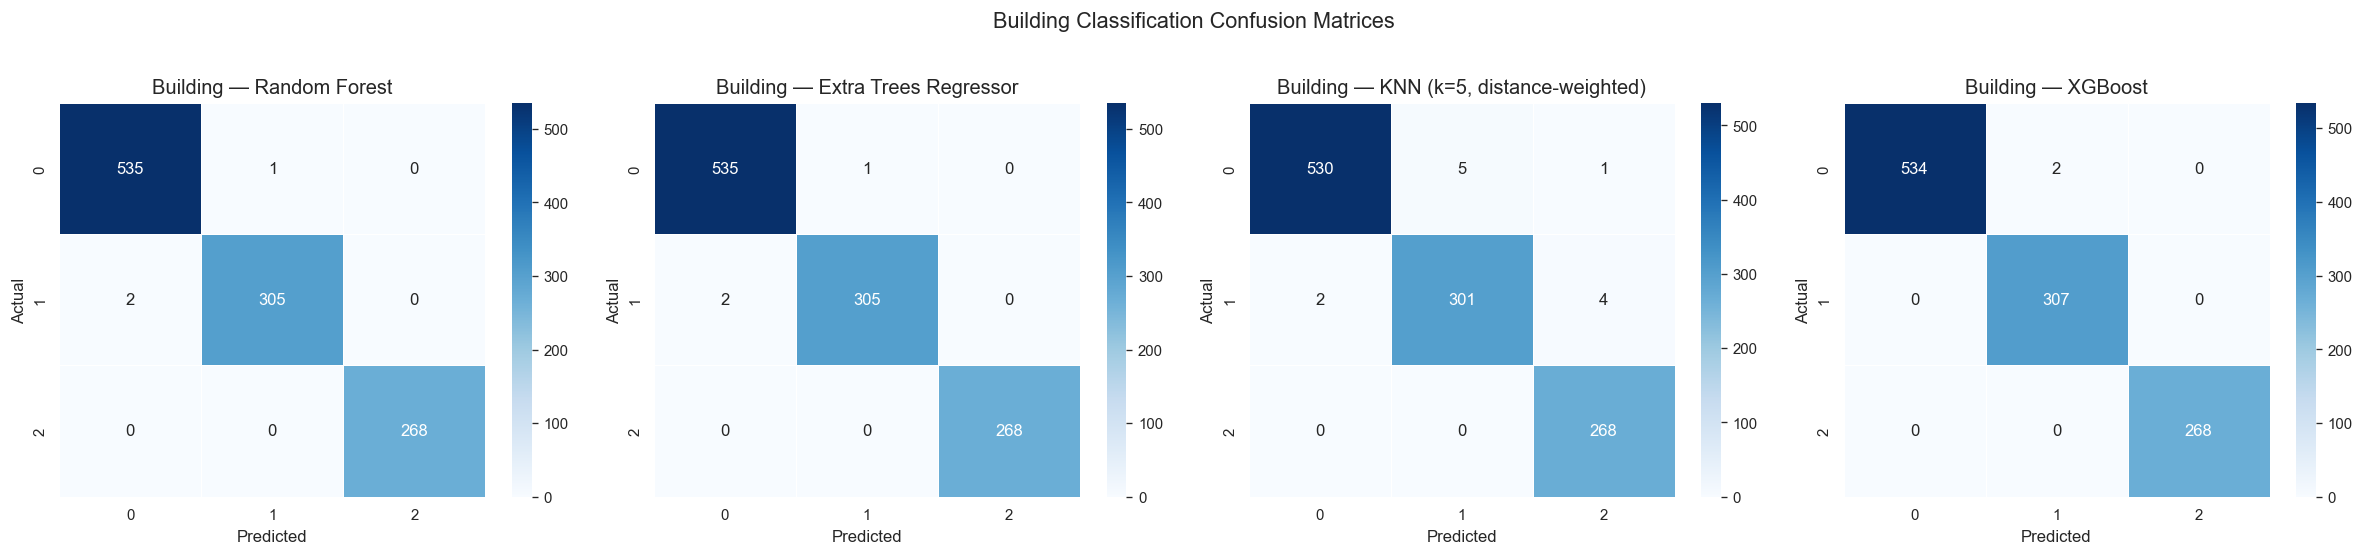

Saved: /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/figures/eval_building_confusion_matrices.png


In [4]:
# Building confusion matrices for ML models
building_labels = sorted(y_val["BUILDINGID"].unique())

fig, axes = plt.subplots(1, len(ML_MODELS), figsize=(5 * len(ML_MODELS), 4.5))
if len(ML_MODELS) == 1:
    axes = [axes]

for ax, model_name in zip(axes, ML_MODELS):
    plot_confusion_matrix(
        y_val["BUILDINGID"].to_numpy(),
        predictions[model_name]["BUILDINGID"],
        labels=building_labels,
        title=f"Building — {model_name}",
        ax=ax,
        figsize=None,
    )

fig.suptitle("Building Classification Confusion Matrices", fontsize=13, y=1.02)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eval_building_confusion_matrices.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR / 'eval_building_confusion_matrices.png'}")

In [5]:
# Detailed classification reports (per-class precision, recall, F1)
for model_name in ML_MODELS:
    print(f"\n{'─' * 60}")
    print(f"Building Classification Report — {model_name}")
    print(f"{'─' * 60}")
    report = get_classification_report_df(
        y_val["BUILDINGID"].to_numpy(),
        predictions[model_name]["BUILDINGID"],
        target_names=[f"Building {b}" for b in building_labels]
    )
    display(report.style.format("{:.4f}"))


────────────────────────────────────────────────────────────
Building Classification Report — Random Forest
────────────────────────────────────────────────────────────


,precision,recall,f1-score,support
Building 0,0.9963,0.9981,0.9972,536.0000
Building 1,0.9967,0.9935,0.9951,307.0000
Building 2,1.0000,1.0000,1.0000,268.0000
accuracy,0.9973,0.9973,0.9973,0.9973
macro avg,0.9977,0.9972,0.9974,1111.0000
weighted avg,0.9973,0.9973,0.9973,1111.0000



────────────────────────────────────────────────────────────
Building Classification Report — Extra Trees Regressor
────────────────────────────────────────────────────────────


,precision,recall,f1-score,support
Building 0,0.9963,0.9981,0.9972,536.0000
Building 1,0.9967,0.9935,0.9951,307.0000
Building 2,1.0000,1.0000,1.0000,268.0000
accuracy,0.9973,0.9973,0.9973,0.9973
macro avg,0.9977,0.9972,0.9974,1111.0000
weighted avg,0.9973,0.9973,0.9973,1111.0000



────────────────────────────────────────────────────────────
Building Classification Report — KNN (k=5, distance-weighted)
────────────────────────────────────────────────────────────


,precision,recall,f1-score,support
Building 0,0.9962,0.9888,0.9925,536.0000
Building 1,0.9837,0.9805,0.9821,307.0000
Building 2,0.9817,1.0000,0.9908,268.0000
accuracy,0.9892,0.9892,0.9892,0.9892
macro avg,0.9872,0.9898,0.9884,1111.0000
weighted avg,0.9893,0.9892,0.9892,1111.0000



────────────────────────────────────────────────────────────
Building Classification Report — XGBoost
────────────────────────────────────────────────────────────


,precision,recall,f1-score,support
Building 0,1.0000,0.9963,0.9981,536.0000
Building 1,0.9935,1.0000,0.9968,307.0000
Building 2,1.0000,1.0000,1.0000,268.0000
accuracy,0.9982,0.9982,0.9982,0.9982
macro avg,0.9978,0.9988,0.9983,1111.0000
weighted avg,0.9982,0.9982,0.9982,1111.0000


## 5. Task 3 — Floor Classification Evaluation

Evaluate floor prediction using accuracy, macro-F1, and confusion matrices.

In [6]:
# Floor classification metrics for all models
floor_results = []
for model_name, pred in predictions.items():
    metrics = evaluate_classifier(model_name, "FLOOR",
                                  y_val["FLOOR"].to_numpy(),
                                  pred["FLOOR"])
    floor_results.append(metrics)

floor_df = pd.DataFrame(floor_results)
floor_df = floor_df.sort_values("accuracy", ascending=False).reset_index(drop=True)

print("═" * 80)
print("FLOOR CLASSIFICATION RESULTS")
print("═" * 80)
display(floor_df.style.format({
    "accuracy": "{:.4f}",
    "precision": "{:.4f}",
    "recall": "{:.4f}",
    "macro_f1": "{:.4f}",
}).set_caption("Floor Classification Metrics"))

════════════════════════════════════════════════════════════════════════════════
FLOOR CLASSIFICATION RESULTS
════════════════════════════════════════════════════════════════════════════════


,model,target,accuracy,precision,recall,macro_f1
0,Random Forest,FLOOR,0.8992,0.9080,0.8577,0.8744
1,Extra Trees Regressor,FLOOR,0.8992,0.9080,0.8577,0.8744
2,XGBoost,FLOOR,0.8956,0.9075,0.8846,0.8916
3,"KNN (k=5, distance-weighted)",FLOOR,0.7543,0.7722,0.7498,0.7479
4,Dummy Baseline (Mode/Median),FLOOR,0.1548,0.0310,0.2000,0.0536


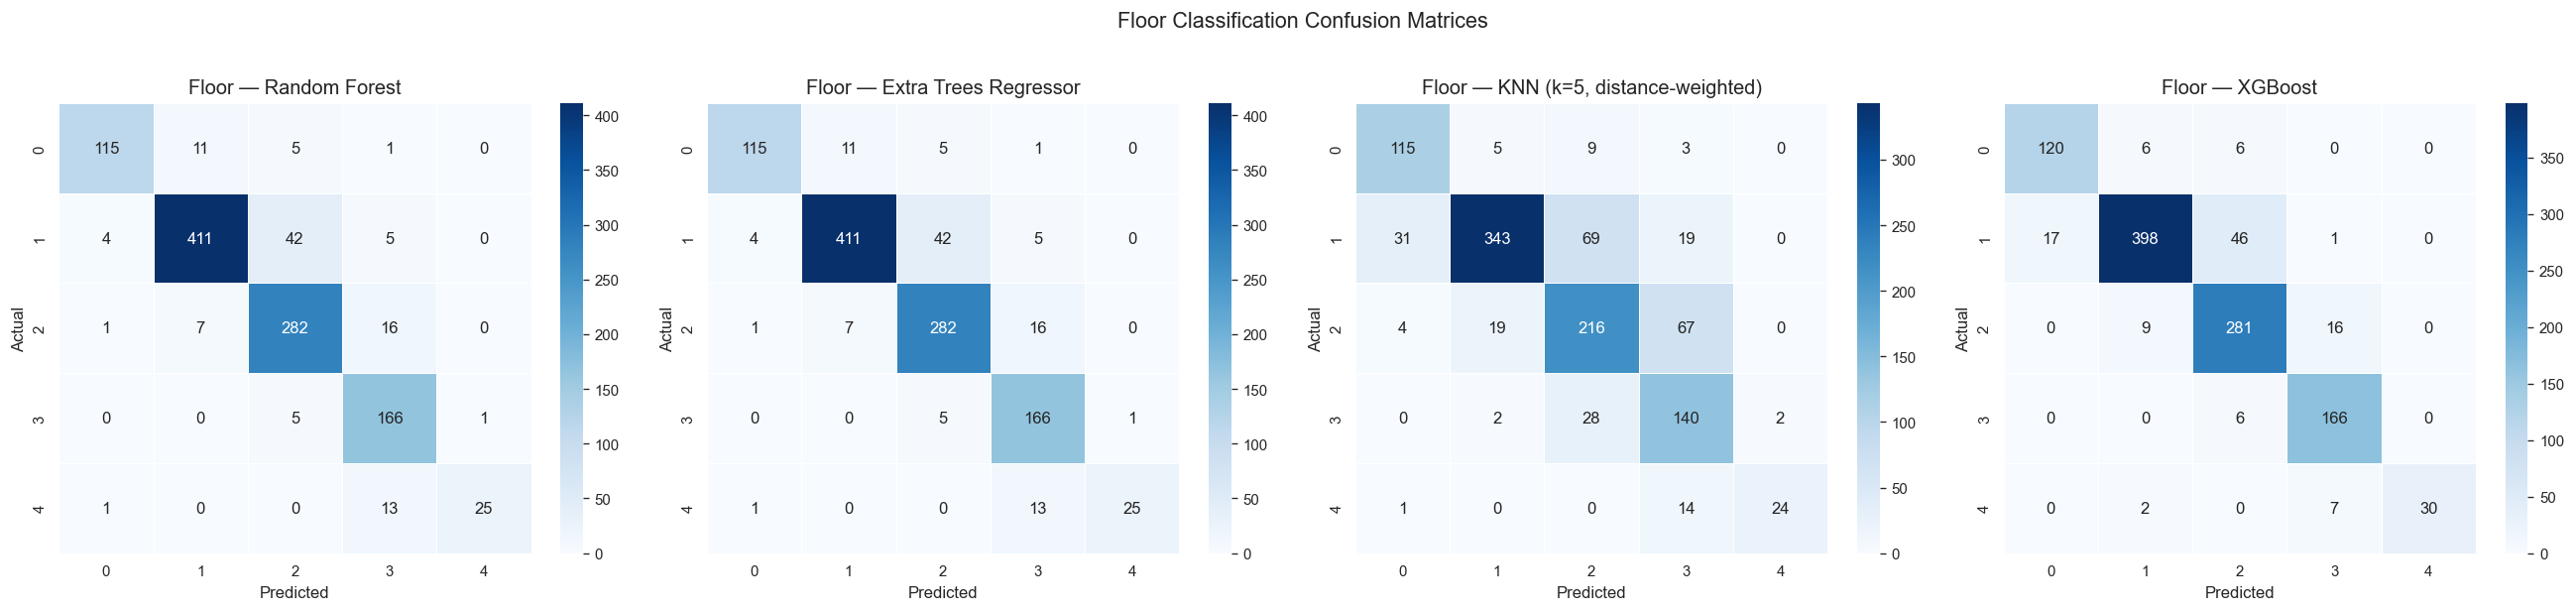

Saved: /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/figures/eval_floor_confusion_matrices.png


In [7]:
# Floor confusion matrices for ML models
floor_labels = sorted(y_val["FLOOR"].unique())

fig, axes = plt.subplots(1, len(ML_MODELS), figsize=(5.5 * len(ML_MODELS), 5))
if len(ML_MODELS) == 1:
    axes = [axes]

for ax, model_name in zip(axes, ML_MODELS):
    plot_confusion_matrix(
        y_val["FLOOR"].to_numpy(),
        predictions[model_name]["FLOOR"],
        labels=floor_labels,
        title=f"Floor — {model_name}",
        ax=ax,
        figsize=None,
    )

fig.suptitle("Floor Classification Confusion Matrices", fontsize=13, y=1.02)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eval_floor_confusion_matrices.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR / 'eval_floor_confusion_matrices.png'}")

In [8]:
# Detailed floor classification reports
for model_name in ML_MODELS:
    print(f"\n{'─' * 60}")
    print(f"Floor Classification Report — {model_name}")
    print(f"{'─' * 60}")
    report = get_classification_report_df(
        y_val["FLOOR"].to_numpy(),
        predictions[model_name]["FLOOR"],
        target_names=[f"Floor {f}" for f in floor_labels]
    )
    display(report.style.format("{:.4f}"))


────────────────────────────────────────────────────────────
Floor Classification Report — Random Forest
────────────────────────────────────────────────────────────


,precision,recall,f1-score,support
Floor 0,0.9504,0.8712,0.9091,132.0000
Floor 1,0.9580,0.8896,0.9226,462.0000
Floor 2,0.8443,0.9216,0.8812,306.0000
Floor 3,0.8259,0.9651,0.8901,172.0000
Floor 4,0.9615,0.6410,0.7692,39.0000
accuracy,0.8992,0.8992,0.8992,0.8992
macro avg,0.9080,0.8577,0.8744,1111.0000
weighted avg,0.9055,0.8992,0.8992,1111.0000



────────────────────────────────────────────────────────────
Floor Classification Report — Extra Trees Regressor
────────────────────────────────────────────────────────────


,precision,recall,f1-score,support
Floor 0,0.9504,0.8712,0.9091,132.0000
Floor 1,0.9580,0.8896,0.9226,462.0000
Floor 2,0.8443,0.9216,0.8812,306.0000
Floor 3,0.8259,0.9651,0.8901,172.0000
Floor 4,0.9615,0.6410,0.7692,39.0000
accuracy,0.8992,0.8992,0.8992,0.8992
macro avg,0.9080,0.8577,0.8744,1111.0000
weighted avg,0.9055,0.8992,0.8992,1111.0000



────────────────────────────────────────────────────────────
Floor Classification Report — KNN (k=5, distance-weighted)
────────────────────────────────────────────────────────────


,precision,recall,f1-score,support
Floor 0,0.7616,0.8712,0.8127,132.0000
Floor 1,0.9295,0.7424,0.8255,462.0000
Floor 2,0.6708,0.7059,0.6879,306.0000
Floor 3,0.5761,0.8140,0.6747,172.0000
Floor 4,0.9231,0.6154,0.7385,39.0000
accuracy,0.7543,0.7543,0.7543,0.7543
macro avg,0.7722,0.7498,0.7479,1111.0000
weighted avg,0.7834,0.7543,0.7597,1111.0000



────────────────────────────────────────────────────────────
Floor Classification Report — XGBoost
────────────────────────────────────────────────────────────


,precision,recall,f1-score,support
Floor 0,0.8759,0.9091,0.8922,132.0000
Floor 1,0.9590,0.8615,0.9076,462.0000
Floor 2,0.8289,0.9183,0.8713,306.0000
Floor 3,0.8737,0.9651,0.9171,172.0000
Floor 4,1.0000,0.7692,0.8696,39.0000
accuracy,0.8956,0.8956,0.8956,0.8956
macro avg,0.9075,0.8846,0.8916,1111.0000
weighted avg,0.9015,0.8956,0.8959,1111.0000


## 6. Task 4 — Coordinate Regression Evaluation

Evaluate coordinate predictions using:
- MAE for each coordinate (Longitude, Latitude)
- Euclidean distance error (mean, median, 90th-percentile)
- RMSE and R²

In [9]:
# Coordinate regression metrics
regression_results = []
prediction_errors = {}  # store per-sample errors for visualisation

for model_name, pred in predictions.items():
    y_true_xy = y_val[REGRESSION_TARGETS].to_numpy(dtype=float)
    y_pred_xy = np.asarray(pred["coordinates"], dtype=float)
    metrics = evaluate_regressor(model_name, y_true_xy, y_pred_xy)
    regression_results.append(metrics)
    prediction_errors[model_name] = position_errors(y_true_xy, y_pred_xy)

regression_df = pd.DataFrame(regression_results)
regression_df = regression_df.sort_values("mean_position_error").reset_index(drop=True)

print("═" * 90)
print("COORDINATE REGRESSION RESULTS")
print("═" * 90)
display(regression_df.style.format({
    "mean_position_error": "{:.2f}",
    "median_position_error": "{:.2f}",
    "p90_position_error": "{:.2f}",
    "mae_longitude": "{:.2f}",
    "mae_latitude": "{:.2f}",
    "coordinate_mae": "{:.2f}",
    "coordinate_rmse": "{:.2f}",
    "coordinate_r2": "{:.4f}",
}).set_caption("Coordinate Regression Metrics (sorted by mean position error)"))

══════════════════════════════════════════════════════════════════════════════════════════
COORDINATE REGRESSION RESULTS
══════════════════════════════════════════════════════════════════════════════════════════


,model,target,mean_position_error,median_position_error,p90_position_error,mae_longitude,mae_latitude,coordinate_mae,coordinate_rmse,coordinate_r2
0,Random Forest,coordinates,12.30,8.15,29.55,8.32,7.51,7.92,12.95,0.9780
1,Extra Trees Regressor,coordinates,12.46,7.66,25.68,8.47,7.54,8.01,15.32,0.9706
2,"KNN (k=5, distance-weighted)",coordinates,13.68,8.20,29.21,8.89,8.76,8.82,16.81,0.9640
3,XGBoost,coordinates,22.70,15.17,47.77,17.51,11.89,14.70,23.14,0.9401
4,Dummy Baseline (Mode/Median),coordinates,161.19,142.34,263.48,139.45,72.62,106.03,128.50,-0.6338


In [30]:
# Combined building + floor accuracy
joint_results = []
for model_name, pred in predictions.items():
    joint = evaluate_building_floor(
        model_name,
        y_val["BUILDINGID"].to_numpy(), pred["BUILDINGID"],
        y_val["FLOOR"].to_numpy(), pred["FLOOR"],
    )
    joint_results.append(joint)

joint_df = pd.DataFrame(joint_results)
joint_df = joint_df.sort_values("building_and_floor_accuracy", ascending=False).reset_index(drop=True)


print("JOINT BUILDING + FLOOR ACCURACY (Hierarchical Location)")
print("═" * 80)
display(joint_df.style.format({
    "building_accuracy": "{:.4f}",
    "floor_accuracy": "{:.4f}",
    "building_and_floor_accuracy": "{:.4f}",
}).set_caption("Joint Building + Floor Accuracy"))

JOINT BUILDING + FLOOR ACCURACY (Hierarchical Location)
════════════════════════════════════════════════════════════════════════════════


,model,building_accuracy,floor_accuracy,building_and_floor_accuracy
0,Random Forest,0.9973,0.8992,0.8974
1,Extra Trees Regressor,0.9973,0.8992,0.8974
2,XGBoost,0.9982,0.8956,0.8956
3,"KNN (k=5, distance-weighted)",0.9892,0.7543,0.7516
4,Dummy Baseline (Mode/Median),0.2412,0.1548,0.0360


## 7. Master Model Comparison Table

Combine all metrics into a single unified comparison table.

In [31]:
# Build unified comparison table
master_rows = []
for model_name in predictions:
    bldg = next(r for r in building_results if r["model"] == model_name)
    flr = next(r for r in floor_results if r["model"] == model_name)
    reg = next(r for r in regression_results if r["model"] == model_name)
    jnt = next(r for r in joint_results if r["model"] == model_name)

    master_rows.append({
        "Model": model_name,
        "Building Acc": bldg["accuracy"],
        "Building F1": bldg["macro_f1"],
        "Floor Acc": flr["accuracy"],
        "Floor F1": flr["macro_f1"],
        "Bldg+Floor Acc": jnt["building_and_floor_accuracy"],
        "Mean Error (m)": reg["mean_position_error"],
        "Median Error (m)": reg["median_position_error"],
        "P90 Error (m)": reg["p90_position_error"],
        "MAE (m)": reg["coordinate_mae"],
        "RMSE (m)": reg["coordinate_rmse"],
        "R²": reg["coordinate_r2"],
    })

master_table = pd.DataFrame(master_rows)
master_table = master_table.sort_values("Median Error (m)").reset_index(drop=True)

print("═" * 110)
print("MASTER MODEL COMPARISON TABLE")
print("═" * 110)
display(master_table.style.format({
    "Building Acc": "{:.4f}", "Building F1": "{:.4f}",
    "Floor Acc": "{:.4f}", "Floor F1": "{:.4f}",
    "Bldg+Floor Acc": "{:.4f}",
    "Mean Error (m)": "{:.2f}", "Median Error (m)": "{:.2f}",
    "P90 Error (m)": "{:.2f}", "MAE (m)": "{:.2f}",
    "RMSE (m)": "{:.2f}", "R²": "{:.4f}",
}).set_caption("Master Model Comparison (sorted by Median Position Error)"))

print(f"\n★ Best model by median error: {master_table.iloc[0]['Model']}")
print(f"  Median error: {master_table.iloc[0]['Median Error (m)']:.2f} m")
print(f"  Mean error:   {master_table.iloc[0]['Mean Error (m)']:.2f} m")

══════════════════════════════════════════════════════════════════════════════════════════════════════════════
MASTER MODEL COMPARISON TABLE
══════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Model,Building Acc,Building F1,Floor Acc,Floor F1,Bldg+Floor Acc,Mean Error (m),Median Error (m),P90 Error (m),MAE (m),RMSE (m),R²
0,Extra Trees Regressor,0.9973,0.9974,0.8992,0.8744,0.8974,12.46,7.66,25.68,8.01,15.32,0.9706
1,Random Forest,0.9973,0.9974,0.8992,0.8744,0.8974,12.30,8.15,29.55,7.92,12.95,0.9780
2,"KNN (k=5, distance-weighted)",0.9892,0.9884,0.7543,0.7479,0.7516,13.68,8.20,29.21,8.82,16.81,0.9640
3,XGBoost,0.9982,0.9983,0.8956,0.8916,0.8956,22.70,15.17,47.77,14.70,23.14,0.9401
4,Dummy Baseline (Mode/Median),0.2412,0.1296,0.1548,0.0536,0.0360,161.19,142.34,263.48,106.03,128.50,-0.6338



★ Best model by median error: Extra Trees Regressor
  Median error: 7.66 m
  Mean error:   12.46 m


## 8. Task 5 — Building-wise and Floor-wise Error Breakdowns

In [32]:
# Building-wise breakdown
bldg_breakdown = building_wise_breakdown(y_val, predictions, REGRESSION_TARGETS)

print("═" * 90)
print("BUILDING-WISE EVALUATION BREAKDOWN")
print("═" * 90)

for model_name in ML_MODELS:
    subset = bldg_breakdown[bldg_breakdown["model"] == model_name]
    print(f"\n── {model_name} ──")
    display(subset.style.format({
        "building_accuracy": "{:.4f}",
        "floor_accuracy": "{:.4f}",
        "floor_macro_f1": "{:.4f}",
        "mean_error_m": "{:.2f}",
        "median_error_m": "{:.2f}",
        "p90_error_m": "{:.2f}",
    }))

══════════════════════════════════════════════════════════════════════════════════════════
BUILDING-WISE EVALUATION BREAKDOWN
══════════════════════════════════════════════════════════════════════════════════════════

── Random Forest ──


,model,building_id,test_samples,building_accuracy,floor_accuracy,floor_macro_f1,mean_error_m,median_error_m,p90_error_m
3,Random Forest,0,536,0.9981,0.9683,0.9650,8.48,5.31,18.82
4,Random Forest,1,307,0.9935,0.8046,0.8199,14.47,10.12,35.69
5,Random Forest,2,268,1.0000,0.8694,0.8436,17.46,11.56,36.95



── Extra Trees Regressor ──


,model,building_id,test_samples,building_accuracy,floor_accuracy,floor_macro_f1,mean_error_m,median_error_m,p90_error_m
6,Extra Trees Regressor,0,536,0.9981,0.9683,0.9650,8.60,5.40,16.76
7,Extra Trees Regressor,1,307,0.9935,0.8046,0.8199,15.44,9.46,37.84
8,Extra Trees Regressor,2,268,1.0000,0.8694,0.8436,16.78,11.53,34.99



── KNN (k=5, distance-weighted) ──


,model,building_id,test_samples,building_accuracy,floor_accuracy,floor_macro_f1,mean_error_m,median_error_m,p90_error_m
9,"KNN (k=5, distance-weighted)",0,536,0.9888,0.7593,0.7471,12.85,6.71,26.95
10,"KNN (k=5, distance-weighted)",1,307,0.9805,0.7101,0.5838,13.07,9.15,28.48
11,"KNN (k=5, distance-weighted)",2,268,1.0000,0.7948,0.7781,16.03,9.98,36.41



── XGBoost ──


,model,building_id,test_samples,building_accuracy,floor_accuracy,floor_macro_f1,mean_error_m,median_error_m,p90_error_m
12,XGBoost,0,536,0.9963,0.9459,0.9441,21.23,11.20,49.85
13,XGBoost,1,307,1.0000,0.7818,0.7974,20.55,17.84,36.99
14,XGBoost,2,268,1.0000,0.9254,0.9098,28.11,19.24,69.13


In [13]:
# Floor-wise breakdown
floor_breakdown = floor_wise_breakdown(y_val, predictions, REGRESSION_TARGETS)

print("═" * 90)
print("FLOOR-WISE EVALUATION BREAKDOWN")
print("═" * 90)

# Show for the best model
best_model = master_table.iloc[0]["Model"]
best_floor = floor_breakdown[floor_breakdown["model"] == best_model]
print(f"\nDetailed floor breakdown for best model: {best_model}")
display(best_floor.style.format({
    "floor_accuracy": "{:.4f}",
    "mean_error_m": "{:.2f}",
    "median_error_m": "{:.2f}",
    "p90_error_m": "{:.2f}",
    "max_error_m": "{:.2f}",
}).set_caption(f"Floor-wise Breakdown — {best_model}"))

══════════════════════════════════════════════════════════════════════════════════════════
FLOOR-WISE EVALUATION BREAKDOWN
══════════════════════════════════════════════════════════════════════════════════════════

Detailed floor breakdown for best model: Extra Trees Regressor


,model,building_id,floor,n_samples,floor_accuracy,mean_error_m,median_error_m,p90_error_m,max_error_m
26,Extra Trees Regressor,0,0,78,0.9231,8.35,5.85,17.77,45.96
27,Extra Trees Regressor,0,1,208,0.9808,6.98,4.38,16.59,36.18
28,Extra Trees Regressor,0,2,165,0.9697,11.00,5.99,16.09,176.41
29,Extra Trees Regressor,0,3,85,0.9765,8.16,5.81,17.60,28.23
30,Extra Trees Regressor,1,0,30,0.7333,17.79,11.50,33.94,93.61
31,Extra Trees Regressor,1,1,143,0.6853,14.69,8.55,38.25,72.24
32,Extra Trees Regressor,1,2,87,0.9540,15.87,10.75,35.62,93.00
33,Extra Trees Regressor,1,3,47,0.9362,15.43,8.02,32.49,81.65
34,Extra Trees Regressor,2,0,24,0.8750,13.17,8.15,32.35,58.55
35,Extra Trees Regressor,2,1,111,0.9820,12.51,9.93,23.95,72.60


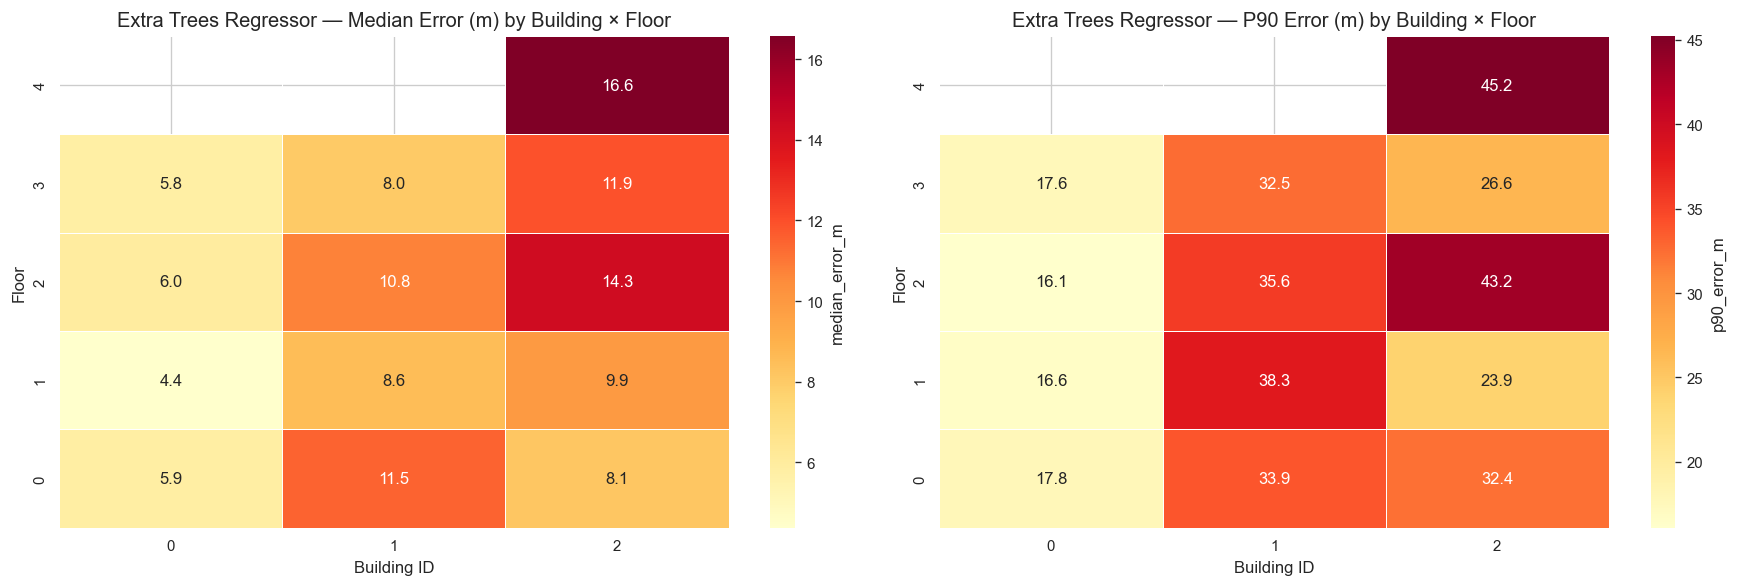

Saved: /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/figures/eval_floor_error_heatmap.png


In [33]:
# Floor-error heatmap for the best model
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_floor_error_heatmap(
    floor_breakdown, best_model, metric="median_error_m",
    title=f"{best_model} — Median Error (m) by Building × Floor",
    ax=axes[0],
)
plot_floor_error_heatmap(
    floor_breakdown, best_model, metric="p90_error_m",
    title=f"{best_model} — P90 Error (m) by Building × Floor",
    ax=axes[1],
)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "eval_floor_error_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR / 'eval_floor_error_heatmap.png'}")

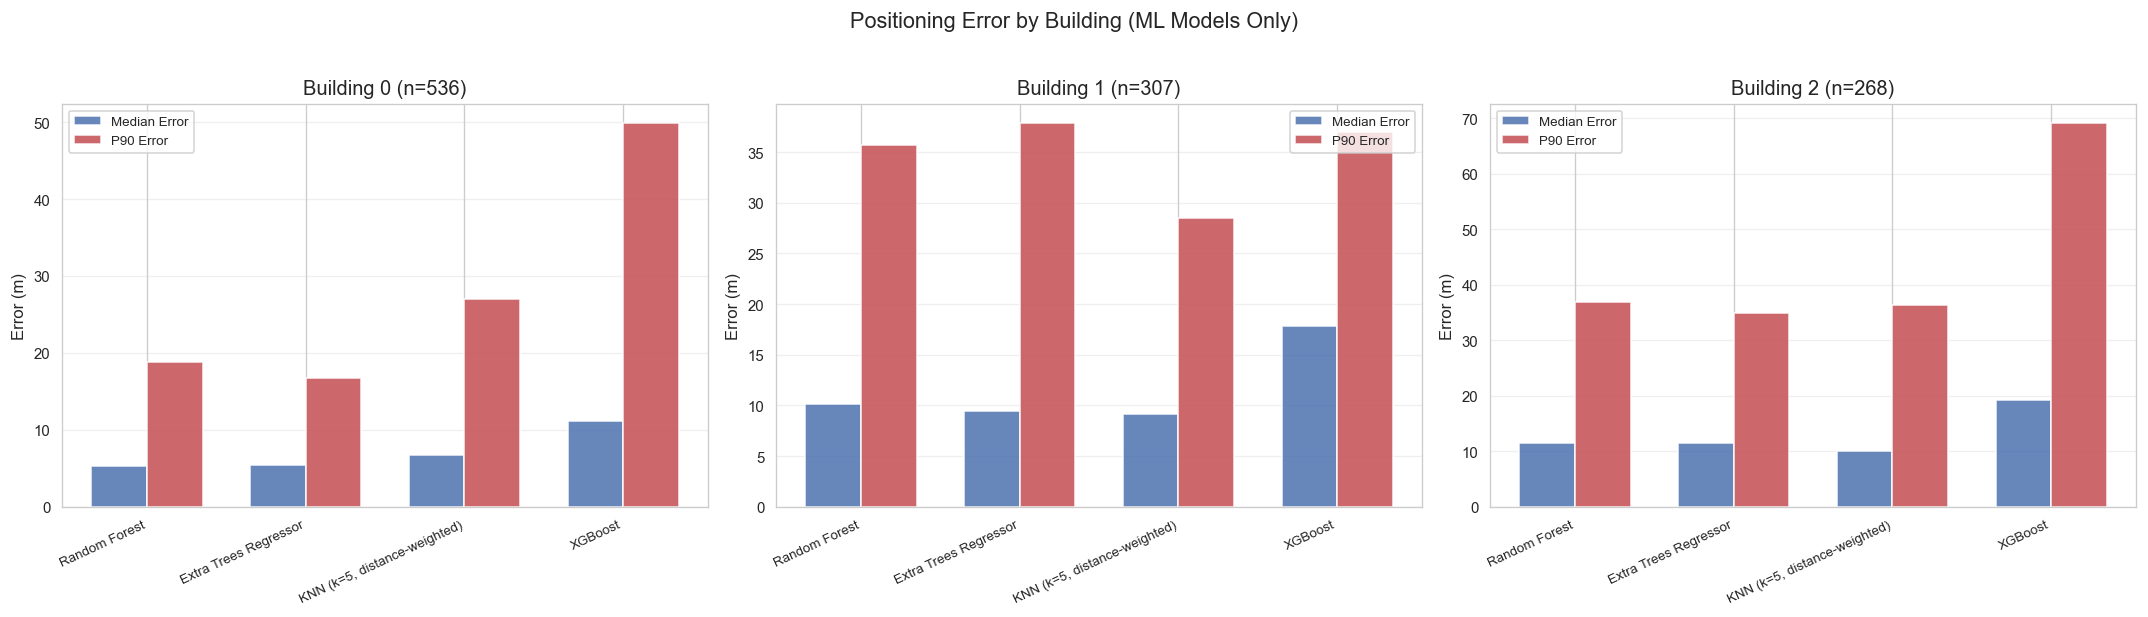

Saved: /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/figures/eval_building_error_comparison.png


In [34]:
# Building-wise comparison bar chart
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, building in enumerate(sorted(y_val["BUILDINGID"].unique())):
    bldg_data = bldg_breakdown[
        (bldg_breakdown["building_id"] == building) &
        (~bldg_breakdown["model"].str.contains("Dummy"))
    ]
    ax = axes[i]
    x = np.arange(len(bldg_data))
    width = 0.35

    ax.bar(x - width/2, bldg_data["median_error_m"], width,
           label="Median Error", color="#4C72B0", alpha=0.85)
    ax.bar(x + width/2, bldg_data["p90_error_m"], width,
           label="P90 Error", color="#C44E52", alpha=0.85)

    ax.set_xticks(x)
    ax.set_xticklabels(bldg_data["model"], rotation=25, ha="right", fontsize=8)
    ax.set_ylabel("Error (m)")
    ax.set_title(f"Building {building} (n={bldg_data.iloc[0]['test_samples']})")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, axis="y")

fig.suptitle("Positioning Error by Building (ML Models Only)", fontsize=13, y=1.02)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eval_building_error_comparison.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR / 'eval_building_error_comparison.png'}")

## 9. Task 6 — Visualizations

### 9.1 Error Distribution Histograms

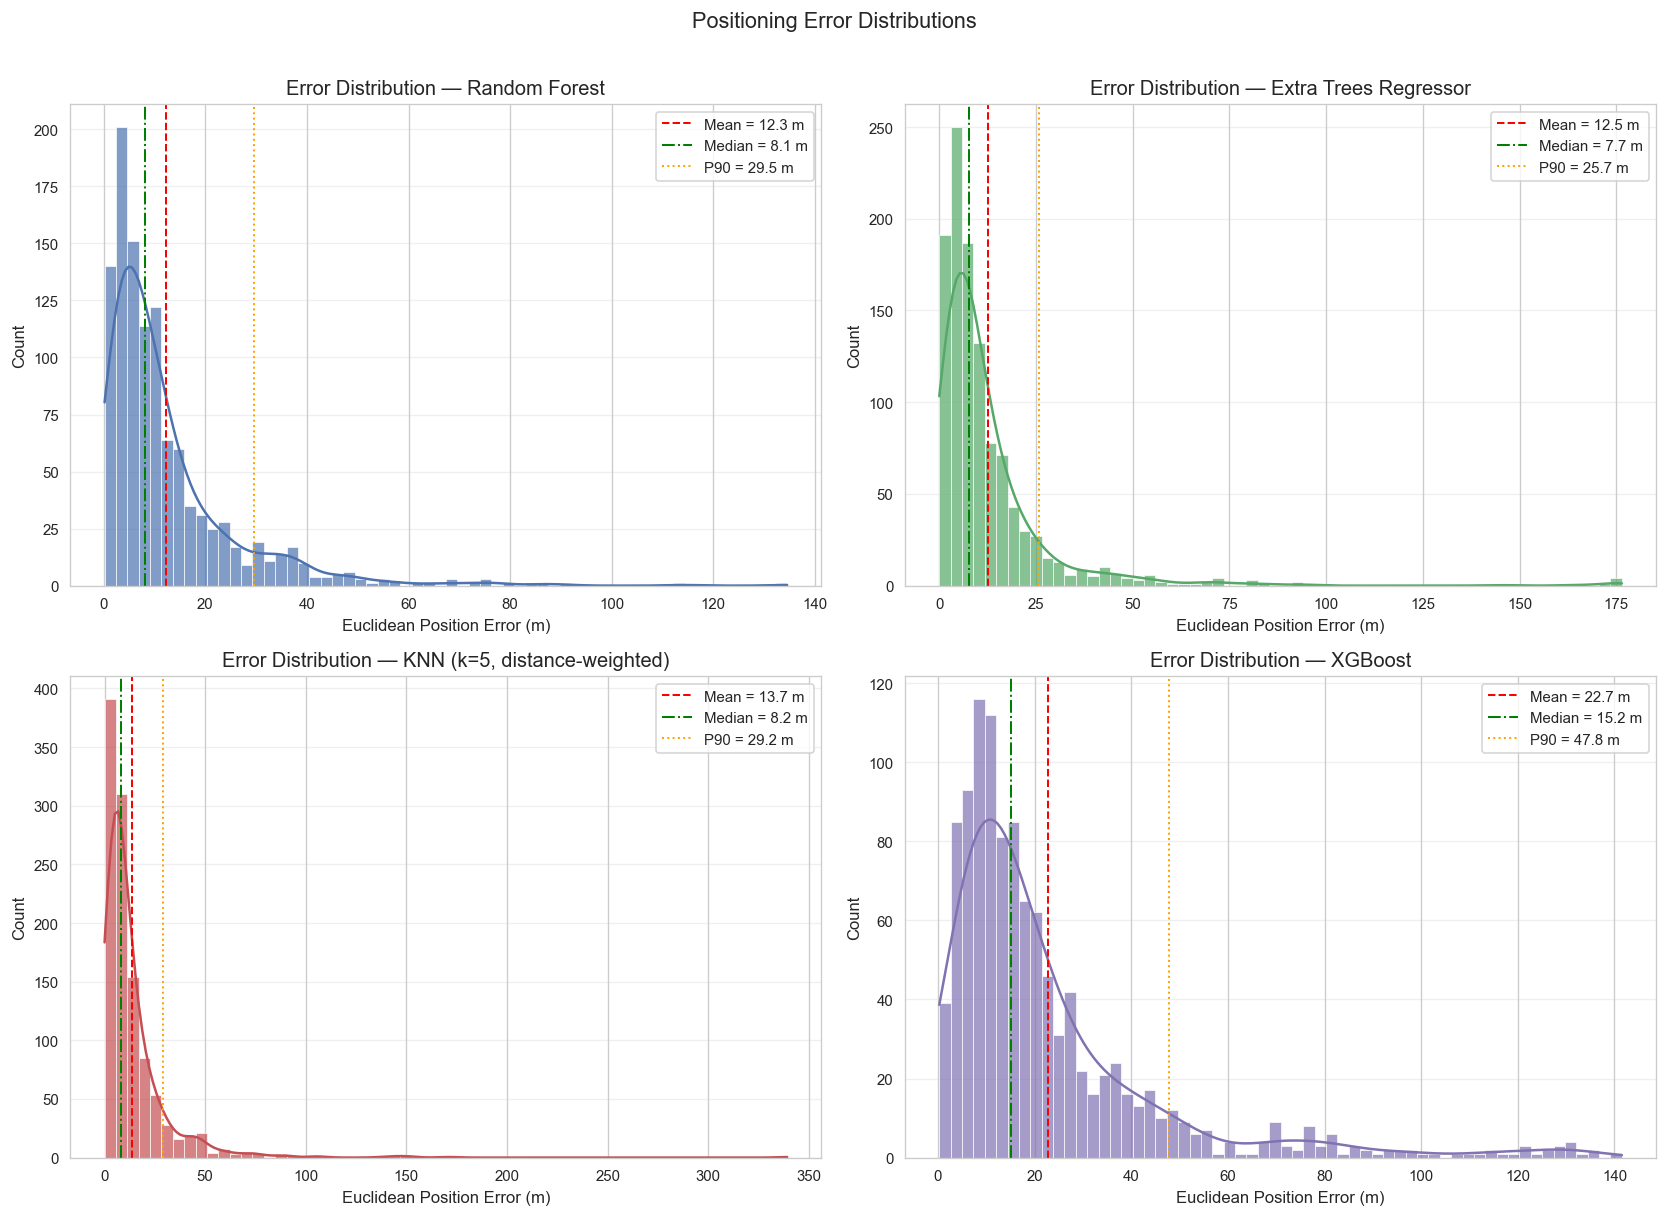

Saved: /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/figures/eval_error_distributions.png


In [35]:
# Error distribution for each ML model
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]
for idx, model_name in enumerate(ML_MODELS):
    plot_error_distribution(
        prediction_errors[model_name],
        title=f"Error Distribution — {model_name}",
        ax=axes[idx],
        color=colors[idx % len(colors)],
    )

# If fewer than 4 models, hide unused axes
for idx in range(len(ML_MODELS), 4):
    axes[idx].set_visible(False)

fig.suptitle("Positioning Error Distributions", fontsize=13, y=1.01)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eval_error_distributions.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR / 'eval_error_distributions.png'}")

### 9.2 Cumulative Distribution Function (CDF) of Positioning Error

  Random Forest: 50% of samples < 8.1m, 90% < 29.5m
  Extra Trees Regressor: 50% of samples < 7.7m, 90% < 25.7m
  KNN (k=5, distance-weighted): 50% of samples < 8.2m, 90% < 29.2m
  XGBoost: 50% of samples < 15.2m, 90% < 47.8m


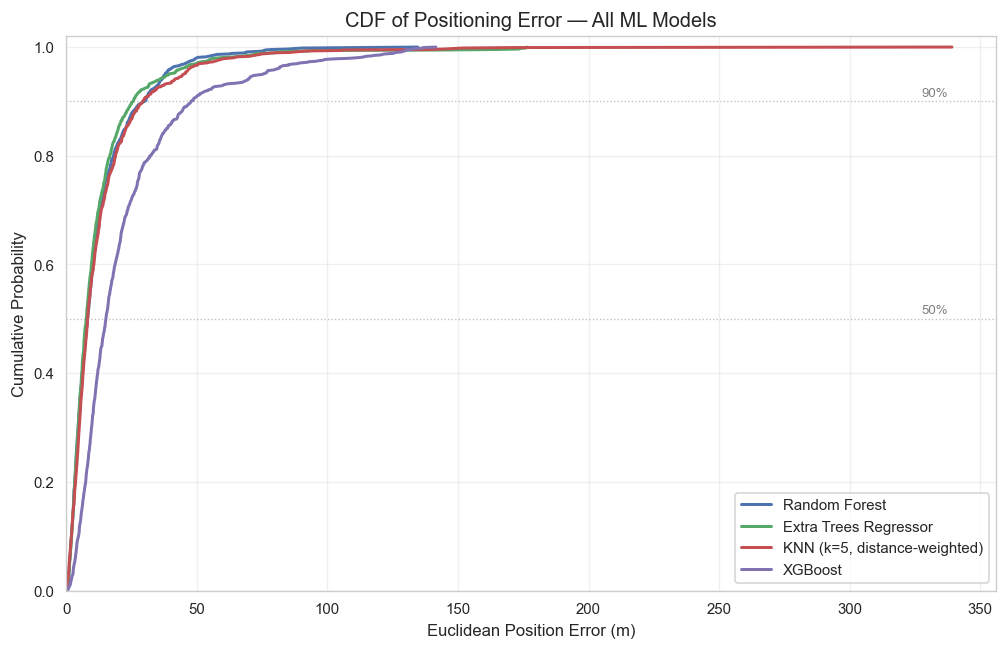

Saved: /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/figures/eval_error_cdf.png


In [36]:
# CDF comparison across all ML models
ml_errors = {m: prediction_errors[m] for m in ML_MODELS}

fig, ax = plt.subplots(figsize=(10, 6))
plot_error_cdf(ml_errors, title="CDF of Positioning Error — All ML Models", ax=ax)

# Add annotations for key thresholds
for model_name, errors in ml_errors.items():
    median = np.median(errors)
    p90 = np.percentile(errors, 90)
    print(f"  {model_name}: 50% of samples < {median:.1f}m, 90% < {p90:.1f}m")

fig.savefig(FIGURES_DIR / "eval_error_cdf.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR / 'eval_error_cdf.png'}")

### 9.3 Model Comparison Bar Chart

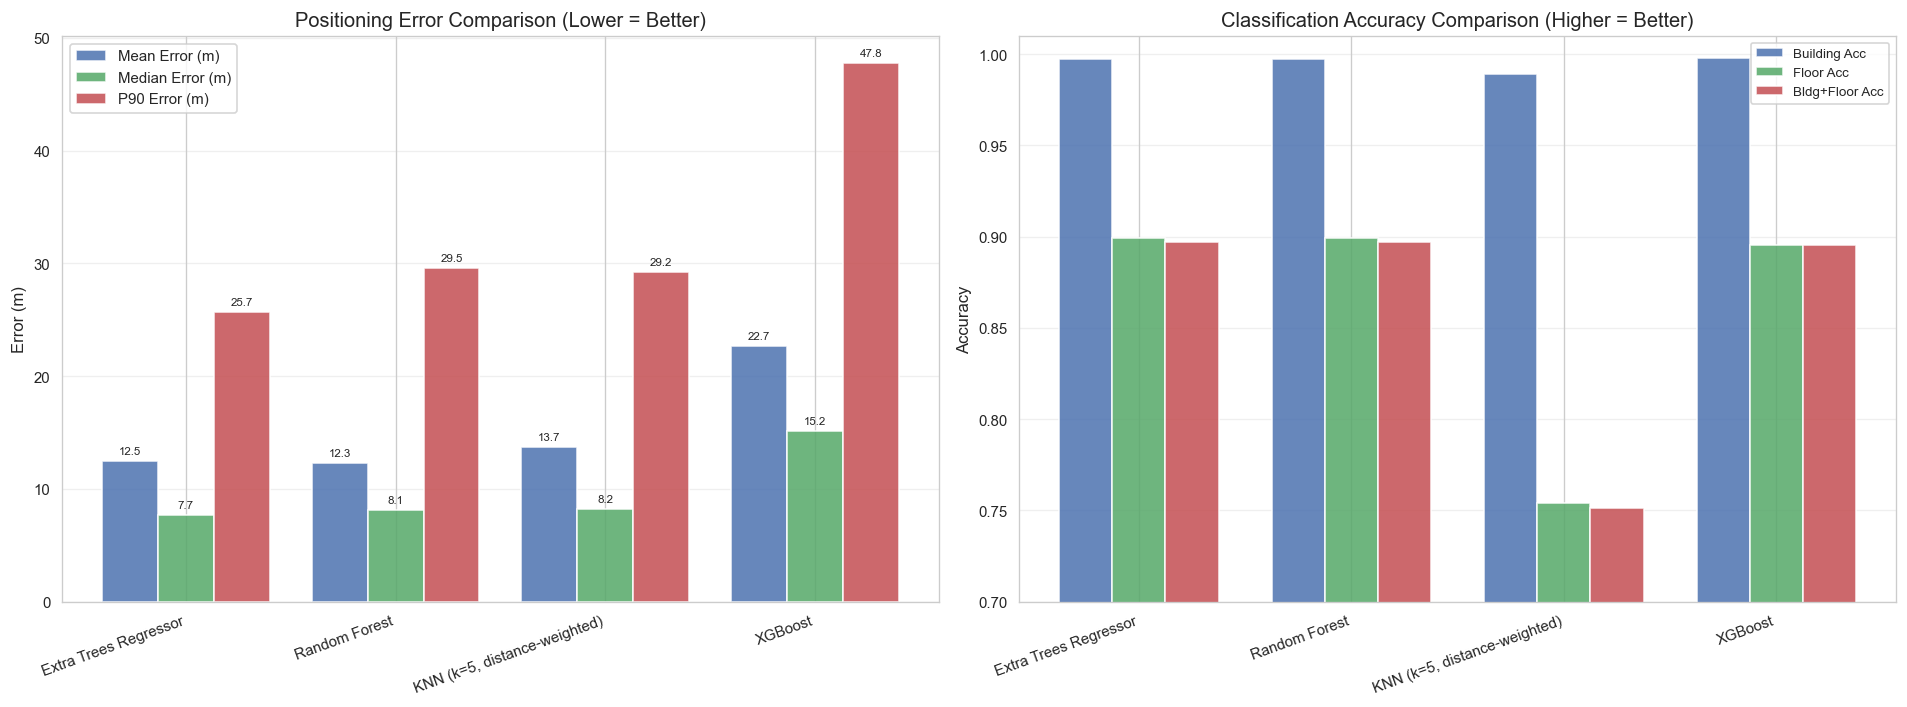

Saved: /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/figures/eval_model_comparison.png


In [37]:
# Model comparison bar chart (excluding dummy baseline)
ml_master = master_table[~master_table["Model"].str.contains("Dummy")].reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Positioning error comparison
plot_model_comparison(
    ml_master,
    metrics=["Mean Error (m)", "Median Error (m)", "P90 Error (m)"],
    title="Positioning Error Comparison (Lower = Better)",
    ax=axes[0],
)

# Classification accuracy comparison
x = np.arange(len(ml_master))
width = 0.25
axes[1].bar(x - width, ml_master["Building Acc"], width,
            label="Building Acc", color="#4C72B0", alpha=0.85)
axes[1].bar(x, ml_master["Floor Acc"], width,
            label="Floor Acc", color="#55A868", alpha=0.85)
axes[1].bar(x + width, ml_master["Bldg+Floor Acc"], width,
            label="Bldg+Floor Acc", color="#C44E52", alpha=0.85)
axes[1].set_xticks(x)
axes[1].set_xticklabels(ml_master["Model"], rotation=20, ha="right")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Classification Accuracy Comparison (Higher = Better)")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3, axis="y")
axes[1].set_ylim(0.7, 1.01)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "eval_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR / 'eval_model_comparison.png'}")

### 9.4 Actual vs Predicted Coordinate Scatter Plots

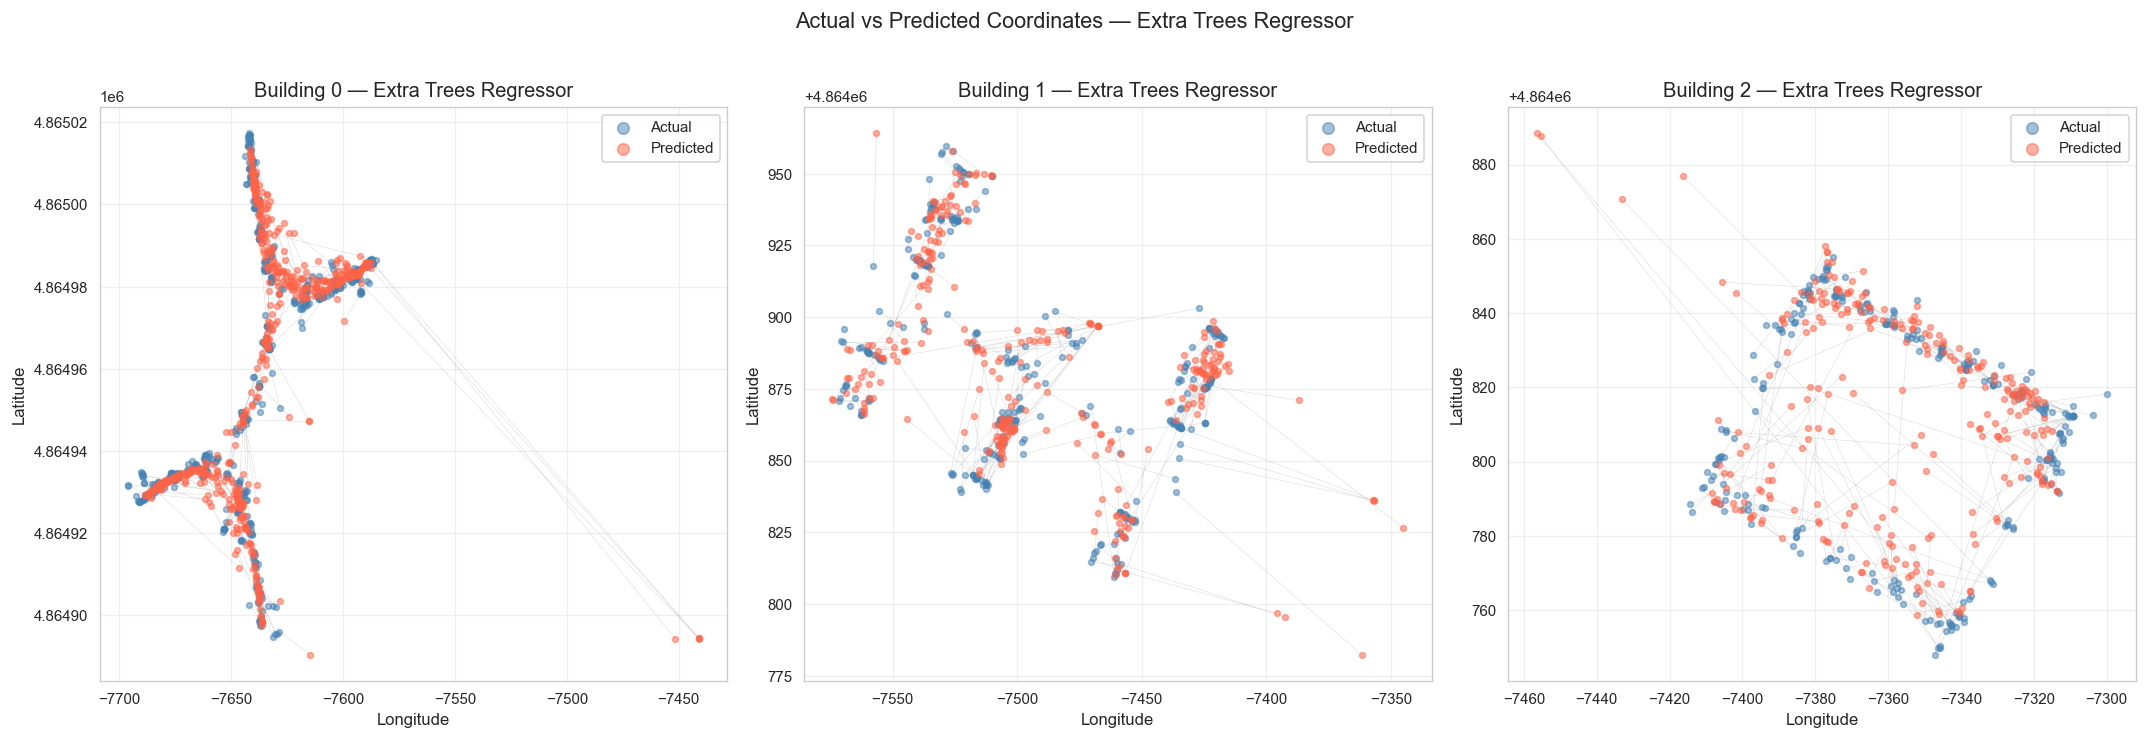

Saved: /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/figures/eval_actual_vs_predicted.png


In [38]:
# Actual vs predicted coordinates for best model, split by building
best_pred = predictions[best_model]
y_true_xy = y_val[REGRESSION_TARGETS].to_numpy(dtype=float)
y_pred_xy = np.asarray(best_pred["coordinates"], dtype=float)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, building in enumerate(sorted(y_val["BUILDINGID"].unique())):
    mask = y_val["BUILDINGID"].to_numpy() == building
    plot_actual_vs_predicted(
        y_true_xy[mask],
        y_pred_xy[mask],
        title=f"Building {building} — {best_model}",
        ax=axes[i],
        figsize=None,
    )

fig.suptitle(f"Actual vs Predicted Coordinates — {best_model}", fontsize=13, y=1.02)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eval_actual_vs_predicted.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR / 'eval_actual_vs_predicted.png'}")

### 9.5 Spatial Error Plots

Colour-coded error maps reveal geographic patterns: areas with sparse AP coverage or unusual building geometry typically show higher errors.

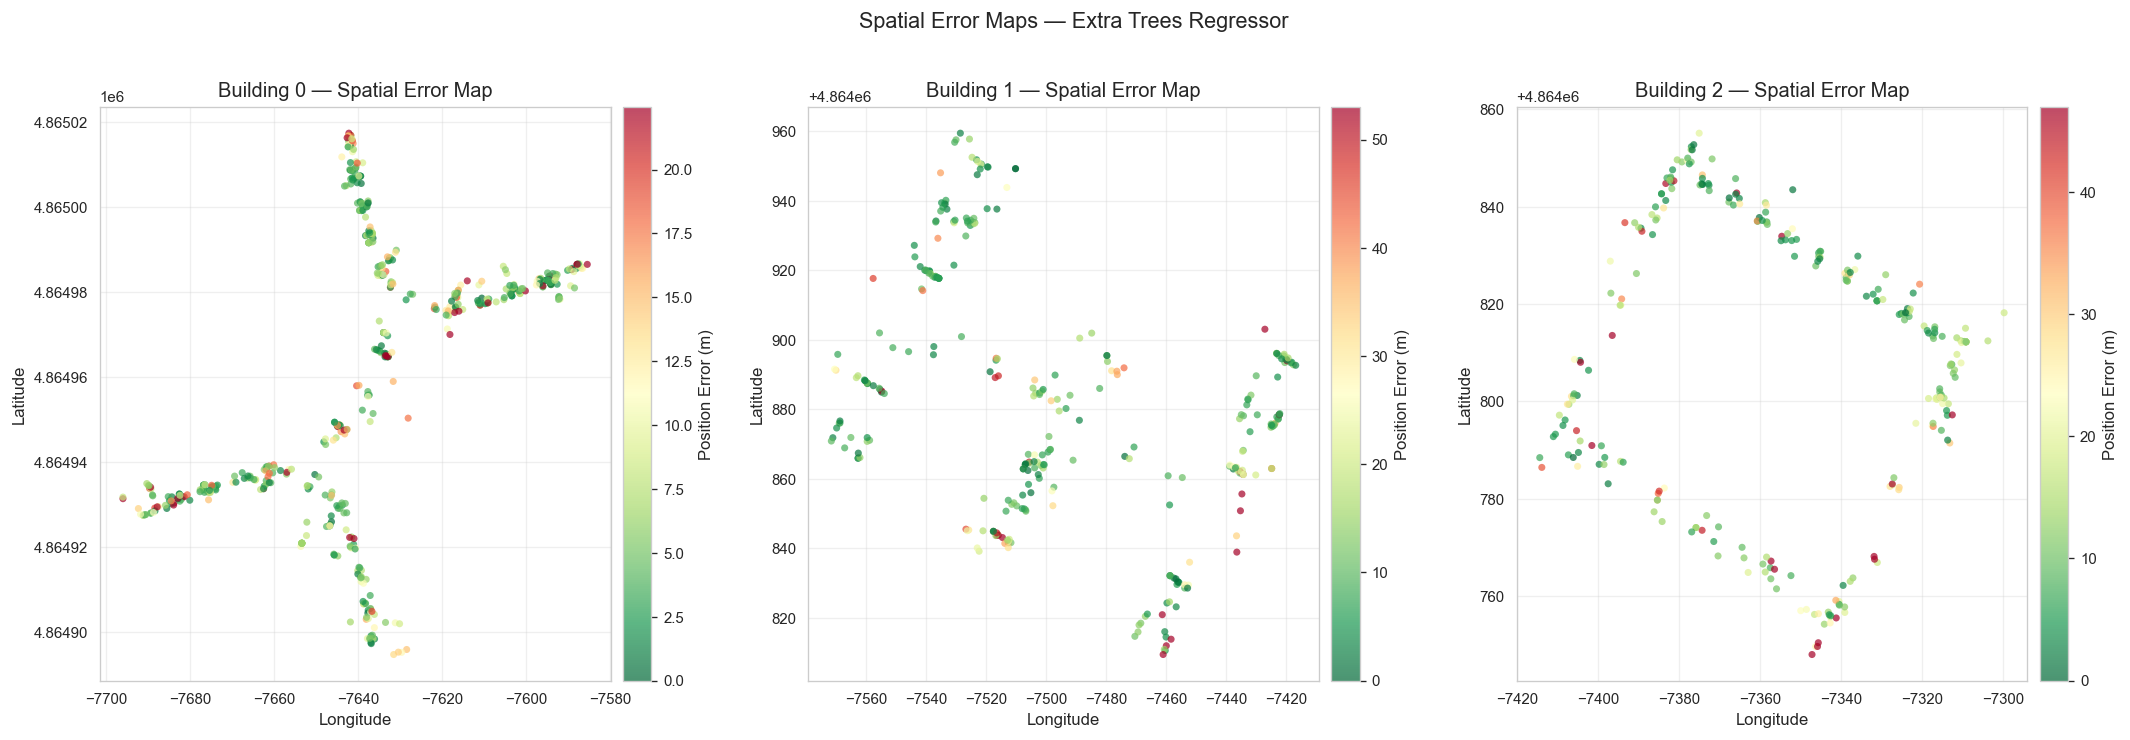

Saved: /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/figures/eval_spatial_error_maps.png


In [39]:
# Spatial error maps per building for best model
best_errors = prediction_errors[best_model]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, building in enumerate(sorted(y_val["BUILDINGID"].unique())):
    mask = y_val["BUILDINGID"].to_numpy() == building
    plot_spatial_errors(
        y_true_xy[mask],
        best_errors[mask],
        title=f"Building {building} — Spatial Error Map",
        ax=axes[i],
        figsize=None,
    )

fig.suptitle(f"Spatial Error Maps — {best_model}", fontsize=13, y=1.02)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eval_spatial_error_maps.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR / 'eval_spatial_error_maps.png'}")

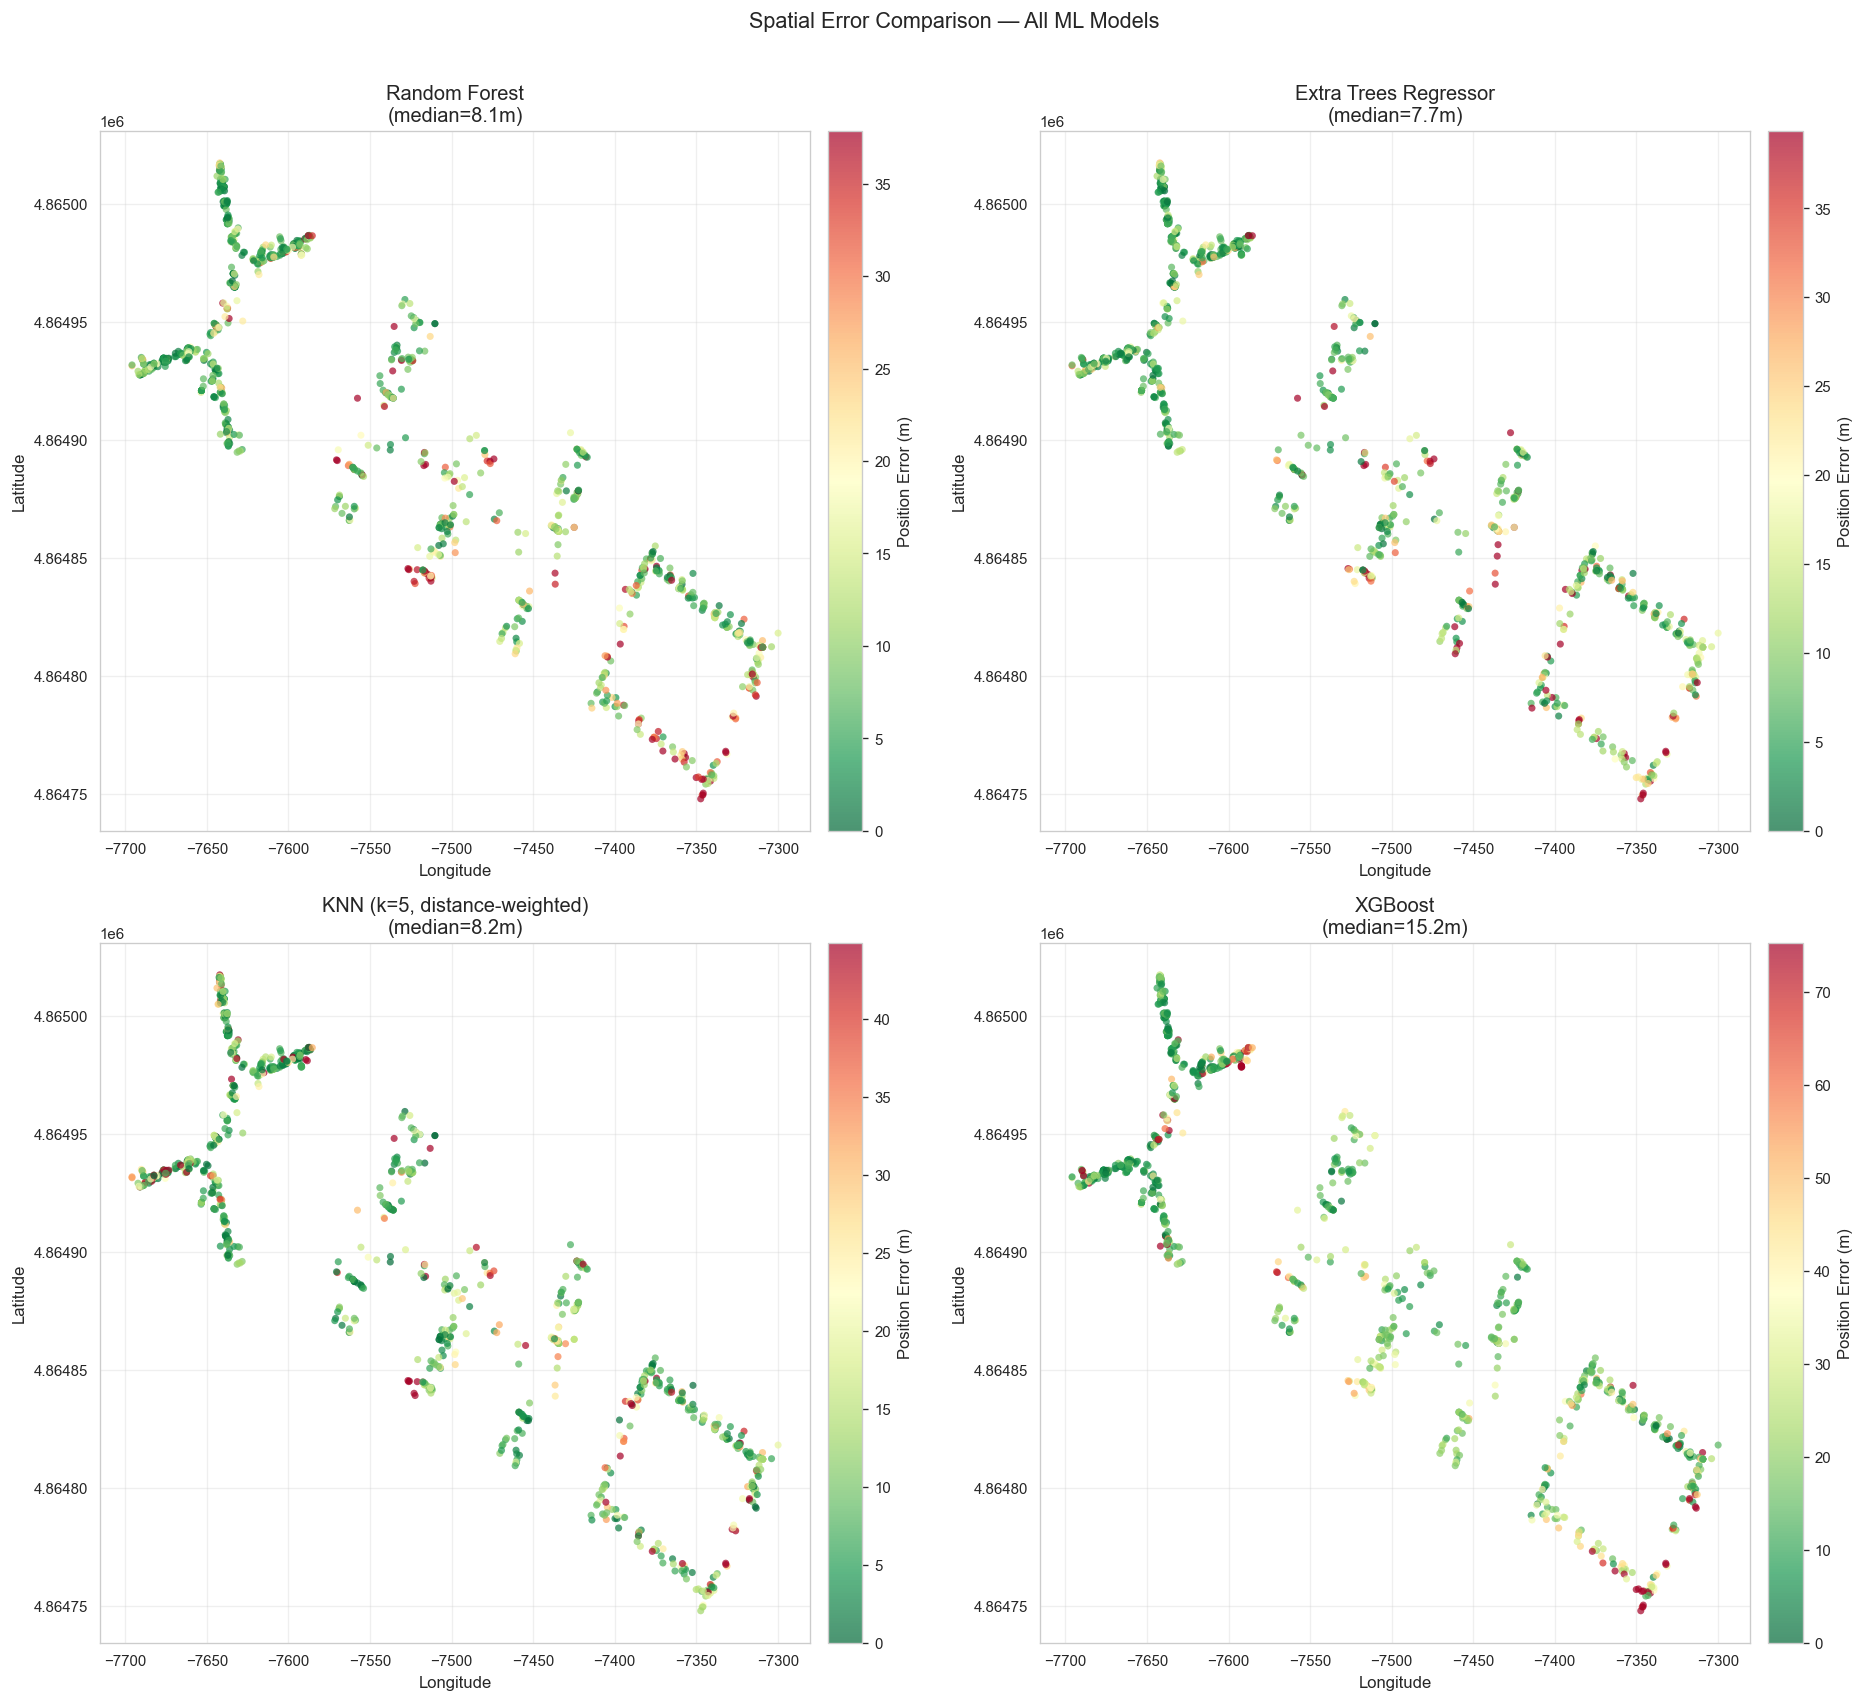

Saved: /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/figures/eval_spatial_error_all_models.png


In [21]:
# All-models spatial error comparison (full dataset)
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.flatten()

for idx, model_name in enumerate(ML_MODELS):
    err = prediction_errors[model_name]
    plot_spatial_errors(
        y_true_xy,
        err,
        title=f"{model_name}\n(median={np.median(err):.1f}m)",
        ax=axes[idx],
        figsize=None,
    )

for idx in range(len(ML_MODELS), 4):
    axes[idx].set_visible(False)

fig.suptitle("Spatial Error Comparison — All ML Models", fontsize=13, y=1.01)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eval_spatial_error_all_models.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR / 'eval_spatial_error_all_models.png'}")

### 9.6 Coordinate-Error Distribution (Per-Axis Analysis)

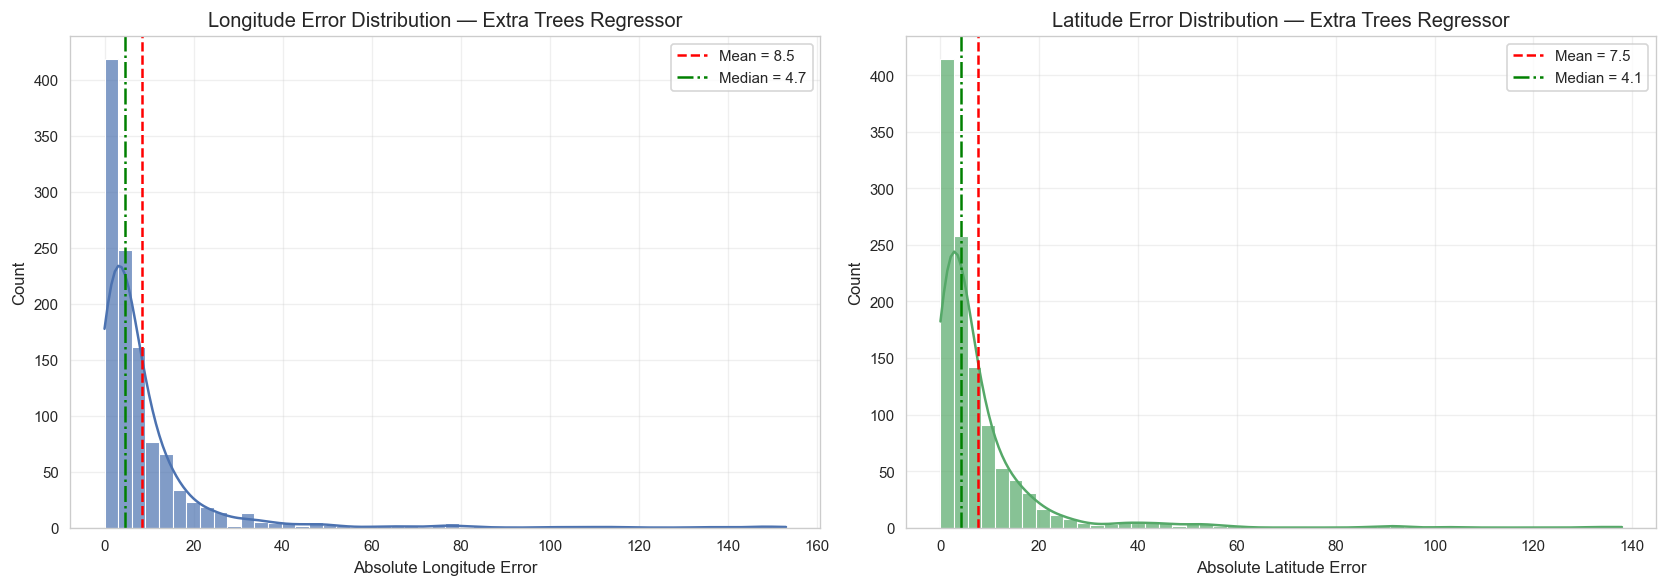

Saved: /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/figures/eval_coordinate_error_distribution.png


In [22]:
# Per-coordinate error analysis for best model
best_pred_xy = np.asarray(predictions[best_model]["coordinates"], dtype=float)
lon_errors = np.abs(y_true_xy[:, 0] - best_pred_xy[:, 0])
lat_errors = np.abs(y_true_xy[:, 1] - best_pred_xy[:, 1])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Longitude error
sns.histplot(lon_errors, bins=50, kde=True, color="#4C72B0", ax=axes[0],
             edgecolor="white", alpha=0.7)
axes[0].axvline(np.mean(lon_errors), color="red", linestyle="--",
                label=f"Mean = {np.mean(lon_errors):.1f}")
axes[0].axvline(np.median(lon_errors), color="green", linestyle="-.",
                label=f"Median = {np.median(lon_errors):.1f}")
axes[0].set_xlabel("Absolute Longitude Error")
axes[0].set_ylabel("Count")
axes[0].set_title(f"Longitude Error Distribution — {best_model}")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Latitude error
sns.histplot(lat_errors, bins=50, kde=True, color="#55A868", ax=axes[1],
             edgecolor="white", alpha=0.7)
axes[1].axvline(np.mean(lat_errors), color="red", linestyle="--",
                label=f"Mean = {np.mean(lat_errors):.1f}")
axes[1].axvline(np.median(lat_errors), color="green", linestyle="-.",
                label=f"Median = {np.median(lat_errors):.1f}")
axes[1].set_xlabel("Absolute Latitude Error")
axes[1].set_ylabel("Count")
axes[1].set_title(f"Latitude Error Distribution — {best_model}")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "eval_coordinate_error_distribution.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR / 'eval_coordinate_error_distribution.png'}")

## 10. Task 7 — Failure Case Analysis

Investigate the worst predictions to understand systematic failure modes:
- Cross-floor confusion (predicted wrong floor)
- Cross-building errors (rare but catastrophic)
- Large coordinate errors within correctly-classified building+floor

In [23]:
# Failure case analysis for the best model
failures = failure_case_analysis(
    y_val, predictions, best_model,
    top_n=30, regression_targets=REGRESSION_TARGETS
)

display_cols = [
    "BUILDINGID", "FLOOR", "pred_building", "pred_floor",
    "building_correct", "floor_correct", "floor_off_by",
    "position_error_m"
]

print("═" * 90)
print(f"TOP 30 WORST PREDICTIONS — {best_model}")
print("═" * 90)
display(failures[display_cols].style.format({
    "position_error_m": "{:.2f}",
}).set_caption("Worst-predicted samples (sorted by descending position error)"))

══════════════════════════════════════════════════════════════════════════════════════════
TOP 30 WORST PREDICTIONS — Extra Trees Regressor
══════════════════════════════════════════════════════════════════════════════════════════


,BUILDINGID,FLOOR,pred_building,pred_floor,building_correct,floor_correct,floor_off_by,position_error_m
0,0,2,0,2,True,True,0,176.41
1,2,3,2,3,True,True,0,176.14
2,2,4,2,3,True,False,-1,175.92
3,0,2,0,2,True,True,0,173.79
4,0,2,0,2,True,True,0,173.43
5,0,2,0,2,True,True,0,164.51
6,2,2,2,3,True,False,1,144.51
7,1,0,1,1,True,False,1,93.61
8,1,2,1,2,True,True,0,93.00
9,1,0,1,1,True,False,1,84.60


In [40]:
# Failure pattern summary
print(f"\n{'═' * 70}")
print(f"FAILURE PATTERN ANALYSIS — {best_model}")
print(f"{'═' * 70}")

n_total = len(y_val)
errors = prediction_errors[best_model]
pred = predictions[best_model]

# Floor mispredictions
floor_wrong = y_val["FLOOR"].to_numpy() != pred["FLOOR"]
bldg_wrong = y_val["BUILDINGID"].to_numpy() != pred["BUILDINGID"]

print(f"\n1. Building misclassifications: {bldg_wrong.sum()}/{n_total} "
      f"({100*bldg_wrong.mean():.2f}%)")
if bldg_wrong.sum() > 0:
    print(f"   Mean position error when building wrong: {errors[bldg_wrong].mean():.1f} m")
    print(f"   Mean position error when building correct: {errors[~bldg_wrong].mean():.1f} m")

print(f"\n2. Floor misclassifications: {floor_wrong.sum()}/{n_total} "
      f"({100*floor_wrong.mean():.2f}%)")
if floor_wrong.sum() > 0:
    print(f"   Mean position error when floor wrong: {errors[floor_wrong].mean():.1f} m")
    print(f"   Mean position error when floor correct: {errors[~floor_wrong].mean():.1f} m")

# Floor confusion patterns
print(f"\n3. Floor confusion patterns (among mispredictions):")
if floor_wrong.sum() > 0:
    true_floors = y_val.loc[floor_wrong, "FLOOR"].to_numpy()
    pred_floors = pred["FLOOR"][floor_wrong]
    off_by = pred_floors - true_floors
    for delta in sorted(np.unique(off_by)):
        count = (off_by == delta).sum()
        print(f"   Floor off by {delta:+d}: {count} samples ({100*count/floor_wrong.sum():.1f}%)")

# Large errors on correctly-classified samples (sparse coverage issue)
correct_both = ~floor_wrong & ~bldg_wrong
high_error_correct = correct_both & (errors > np.percentile(errors, 90))
print(f"\n4. High error despite correct building+floor: {high_error_correct.sum()} samples")
if high_error_correct.sum() > 0:
    print(f"   These samples have correct classification but position error > "
          f"{np.percentile(errors, 90):.1f} m (P90 threshold)")
    print(f"   Mean error: {errors[high_error_correct].mean():.1f} m")
    print(f"   This suggests areas with sparse Wi-Fi AP coverage or ambiguous fingerprints.")


══════════════════════════════════════════════════════════════════════
FAILURE PATTERN ANALYSIS — Extra Trees Regressor
══════════════════════════════════════════════════════════════════════

1. Building misclassifications: 3/1111 (0.27%)
   Mean position error when building wrong: 20.1 m
   Mean position error when building correct: 12.4 m

2. Floor misclassifications: 112/1111 (10.08%)
   Mean position error when floor wrong: 23.9 m
   Mean position error when floor correct: 11.2 m

3. Floor confusion patterns (among mispredictions):
   Floor off by -4: 1 samples (0.9%)
   Floor off by -2: 1 samples (0.9%)
   Floor off by -1: 29 samples (25.9%)
   Floor off by +1: 70 samples (62.5%)
   Floor off by +2: 10 samples (8.9%)
   Floor off by +3: 1 samples (0.9%)

4. High error despite correct building+floor: 73 samples
   These samples have correct classification but position error > 25.7 m (P90 threshold)
   Mean error: 50.6 m
   This suggests areas with sparse Wi-Fi AP coverage or ambig

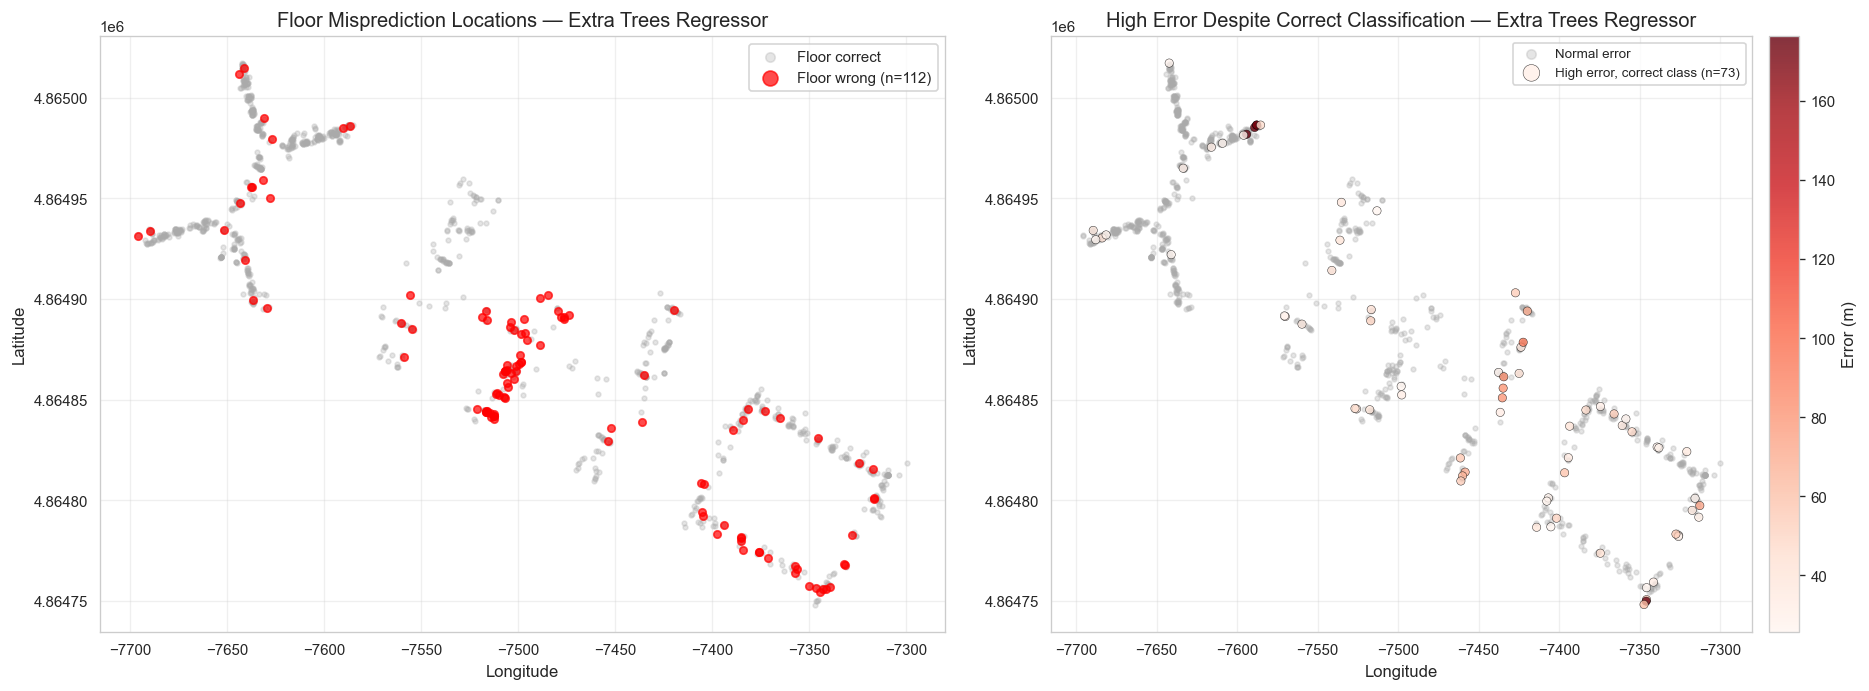

Saved: /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/figures/eval_failure_cases_spatial.png


In [41]:
# Visualize failure cases spatially
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: Highlight floor mispredictions
ax = axes[0]
ax.scatter(y_true_xy[~floor_wrong, 0], y_true_xy[~floor_wrong, 1],
           c="#AAAAAA", s=8, alpha=0.3, label="Floor correct")
if floor_wrong.sum() > 0:
    ax.scatter(y_true_xy[floor_wrong, 0], y_true_xy[floor_wrong, 1],
               c="red", s=20, alpha=0.7, label=f"Floor wrong (n={floor_wrong.sum()})")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(f"Floor Misprediction Locations — {best_model}")
ax.legend(markerscale=2)
ax.grid(True, alpha=0.3)

# Right: Highlight high-error correct-classification cases
ax = axes[1]
ax.scatter(y_true_xy[~high_error_correct, 0], y_true_xy[~high_error_correct, 1],
           c="#AAAAAA", s=8, alpha=0.3, label="Normal error")
if high_error_correct.sum() > 0:
    sc = ax.scatter(
        y_true_xy[high_error_correct, 0],
        y_true_xy[high_error_correct, 1],
        c=errors[high_error_correct], cmap="Reds", s=25, alpha=0.8,
        label=f"High error, correct class (n={high_error_correct.sum()})",
        edgecolors="black", linewidths=0.3,
    )
    plt.colorbar(sc, ax=ax, pad=0.02, label="Error (m)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(f"High Error Despite Correct Classification — {best_model}")
ax.legend(markerscale=2, fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "eval_failure_cases_spatial.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR / 'eval_failure_cases_spatial.png'}")

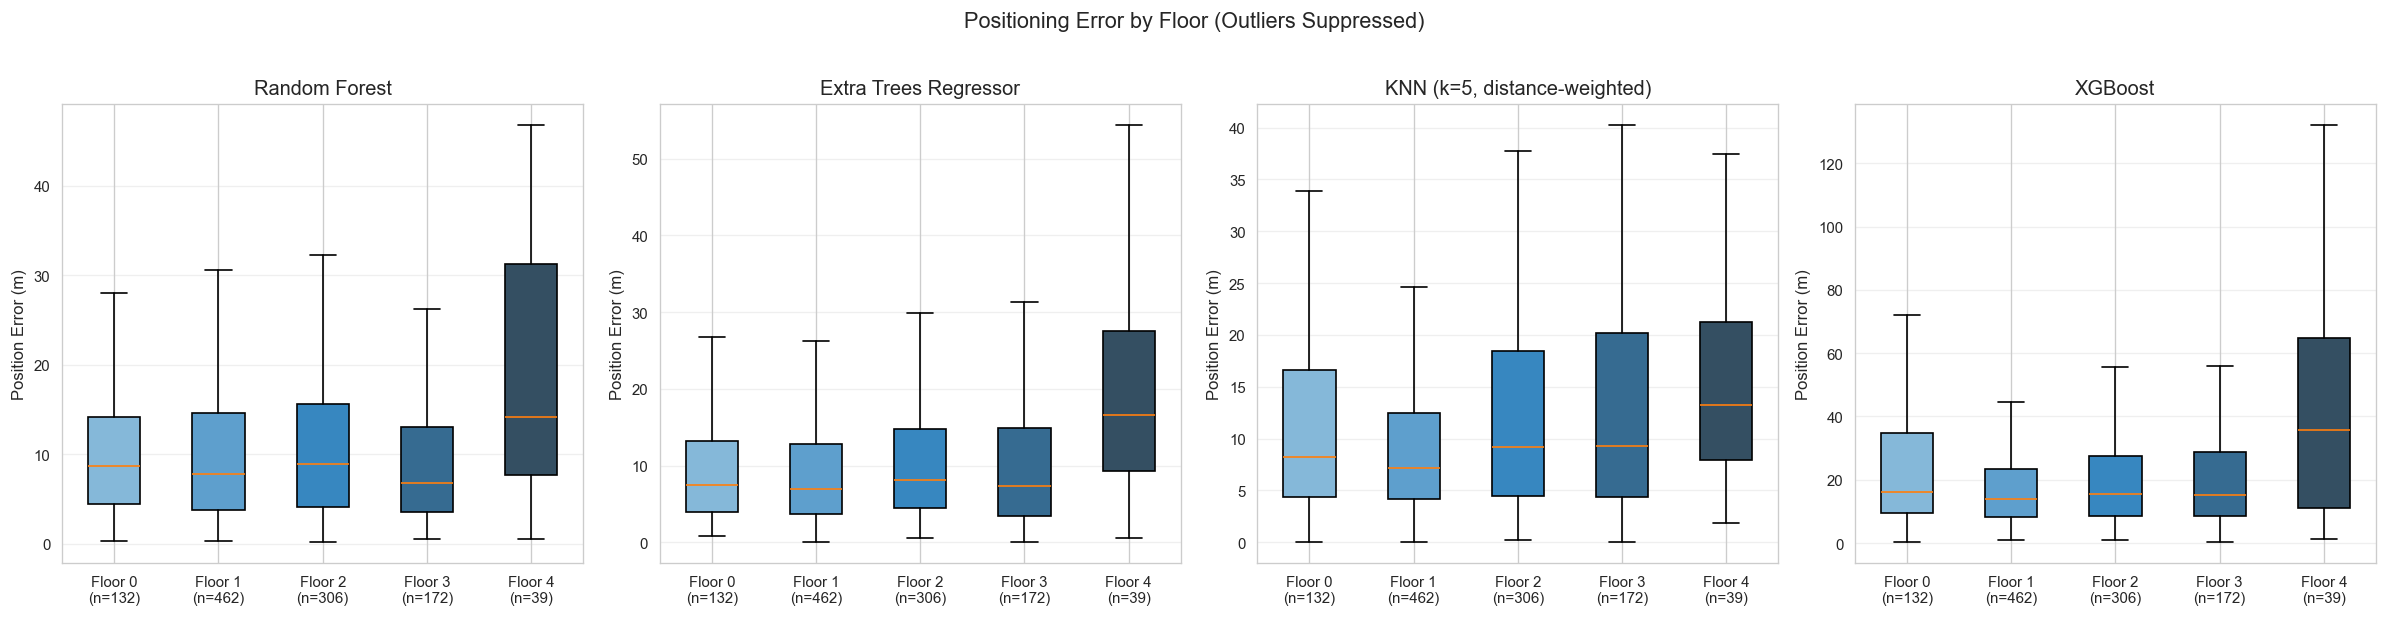

Saved: /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/figures/eval_error_by_floor.png


In [26]:
# Error boxplot by floor — revealing floor-specific difficulty
fig, axes = plt.subplots(1, len(ML_MODELS), figsize=(5 * len(ML_MODELS), 5))
if len(ML_MODELS) == 1:
    axes = [axes]

for ax, model_name in zip(axes, ML_MODELS):
    err = prediction_errors[model_name]
    floor_groups = []
    floor_labels_list = []
    for floor in sorted(y_val["FLOOR"].unique()):
        mask = y_val["FLOOR"].to_numpy() == floor
        floor_groups.append(err[mask])
        floor_labels_list.append(f"Floor {floor}\n(n={mask.sum()})")

    bp = ax.boxplot(floor_groups, tick_labels=floor_labels_list,
                    showfliers=False, patch_artist=True)
    colors = sns.color_palette("Blues_d", len(floor_groups))
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)

    ax.set_ylabel("Position Error (m)")
    ax.set_title(f"{model_name}")
    ax.grid(True, alpha=0.3, axis="y")

fig.suptitle("Positioning Error by Floor (Outliers Suppressed)",
             fontsize=13, y=1.02)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eval_error_by_floor.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR / 'eval_error_by_floor.png'}")

## 11. Export Final Evaluation Artifacts

Save all evaluation tables, breakdowns, and figures generated in this notebook.

In [28]:
# Export evaluation results
print("Exporting evaluation artifacts...")

# 1. Extended classification results with precision and recall
all_classification = building_results + floor_results
extended_classification_df = pd.DataFrame(all_classification)
extended_classification_df.to_csv(
    METRICS_DIR / "eval_classification_detailed.csv", index=False)
print(f"  eval_classification_detailed.csv")

# 2. Extended regression results with per-coordinate MAE
regression_df.to_csv(
    METRICS_DIR / "eval_regression_detailed.csv", index=False)
print(f"eval_regression_detailed.csv")

# 3. Master comparison table
master_table.to_csv(
    METRICS_DIR / "eval_master_comparison.csv", index=False)
master_table.to_csv(
    REPORTS_DIR / "eval_master_comparison.csv", index=False)
print(f"eval_master_comparison.csv")

# 4. Building-wise breakdown
bldg_breakdown.to_csv(
    METRICS_DIR / "eval_building_breakdown.csv", index=False)
print(f"eval_building_breakdown.csv")

# 5. Floor-wise breakdown
floor_breakdown.to_csv(
    METRICS_DIR / "eval_floor_breakdown.csv", index=False)
print(f"eval_floor_breakdown.csv")

# 6. Joint accuracy
joint_df.to_csv(
    METRICS_DIR / "eval_joint_accuracy.csv", index=False)
print(f"eval_joint_accuracy.csv")

# 7. Failure cases
failures.to_csv(
    METRICS_DIR / "eval_failure_cases.csv", index=False)
print(f"eval_failure_cases.csv")

# 8. Summary of figure files saved
eval_figures = sorted(FIGURES_DIR.glob("eval_*.png"))
print(f"\nFigures saved ({len(eval_figures)}):")
for fig_path in eval_figures:
    print(f"{fig_path.name}")

print(f"\n{'═' * 60}")
print("All evaluation artifacts exported successfully.")
print(f"  Metrics: {METRICS_DIR.resolve()}")
print(f"  Reports: {REPORTS_DIR.resolve()}")
print(f"  Figures: {FIGURES_DIR.resolve()}")

Exporting evaluation artifacts...
  eval_classification_detailed.csv
eval_regression_detailed.csv
eval_master_comparison.csv
eval_building_breakdown.csv
eval_floor_breakdown.csv
eval_joint_accuracy.csv
eval_failure_cases.csv

Figures saved (13):
eval_actual_vs_predicted.png
eval_building_confusion_matrices.png
eval_building_error_comparison.png
eval_coordinate_error_distribution.png
eval_error_by_floor.png
eval_error_cdf.png
eval_error_distributions.png
eval_failure_cases_spatial.png
eval_floor_confusion_matrices.png
eval_floor_error_heatmap.png
eval_model_comparison.png
eval_spatial_error_all_models.png
eval_spatial_error_maps.png

════════════════════════════════════════════════════════════
All evaluation artifacts exported successfully.
  Metrics: /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/metrics
  Reports: /Users/soumyatiwari/Desktop/indoor-wifi-positioning/report/model_evaluation
  Figures: /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/figures


## 12. Summary and Key Findings

### Evaluation Summary

In [29]:
print("╔" + "═" * 68 + "╗")
print("║" + " INDOOR POSITIONING SYSTEM — EVALUATION SUMMARY ".center(68) + "║")
print("╠" + "═" * 68 + "╣")

best = master_table.iloc[0]
print(f"║ Best Model: {best['Model']:<55}║")
print(f"║                                                                    ║")
print(f"║ Building Classification:                                           ║")
print(f"║   Accuracy: {best['Building Acc']:.4f}    F1: {best['Building F1']:.4f}" + " " * 33 + "║")
print(f"║                                                                    ║")
print(f"║ Floor Classification:                                              ║")
print(f"║   Accuracy: {best['Floor Acc']:.4f}    F1: {best['Floor F1']:.4f}" + " " * 33 + "║")
print(f"║                                                                    ║")
print(f"║ Positioning Performance:                                           ║")
print(f"║   Mean Error:   {best['Mean Error (m)']:>7.2f} m" + " " * 41 + "║")
print(f"║   Median Error: {best['Median Error (m)']:>7.2f} m" + " " * 41 + "║")
print(f"║   P90 Error:    {best['P90 Error (m)']:>7.2f} m" + " " * 41 + "║")
print(f"║   R²:           {best['R²']:>7.4f}" + " " * 43 + "║")
print(f"║                                                                    ║")
print(f"║ Dataset: {run_info['train_rows_cleaned']} train / {run_info['validation_rows']} val samples" + " " * 26 + "║")
print(f"║ Features: {run_info['n_features']} (after preprocessing)" + " " * 32 + "║")
print("╚" + "═" * 68 + "╝")

print("\n### Key Findings:")
print("")
print("1. **Building classification is essentially solved** — all ML models achieve")
print(f"   >98.9% accuracy. The Wi-Fi fingerprints provide clear building separation.")
print("")
print("2. **Floor classification is the main challenge** — best accuracy ~90%.")
print("   Cross-floor confusion (±1 floor) accounts for the majority of errors.")
print("")
print("3. **Random Forest and Extra Trees achieve best positioning accuracy**")
print(f"   with median errors of ~{master_table.iloc[0]['Median Error (m)']:.1f}m.")
print("")
print("4. **Failure cases cluster in areas with sparse AP coverage** and at")
print("   building edges / floor transitions.")
print("")
print("5. **Building 1 consistently shows higher errors** across all models,")
print("   likely due to its more complex geometry or sparser reference points.")

╔════════════════════════════════════════════════════════════════════╗
║           INDOOR POSITIONING SYSTEM — EVALUATION SUMMARY           ║
╠════════════════════════════════════════════════════════════════════╣
║ Best Model: Extra Trees Regressor                                  ║
║                                                                    ║
║ Building Classification:                                           ║
║   Accuracy: 0.9973    F1: 0.9974                                 ║
║                                                                    ║
║ Floor Classification:                                              ║
║   Accuracy: 0.8992    F1: 0.8744                                 ║
║                                                                    ║
║ Positioning Performance:                                           ║
║   Mean Error:     12.46 m                                         ║
║   Median Error:    7.66 m                                         ║
║   P90 Erro